# 45. New College generalization: Flow Matching 44 vs regression 2.24

**Independent, zero-training transfer test.** Reproduce notebook 36’s physical New College preparation (RealSense IMU, Ouster IMU, Ouster LiDAR odometry), the nominal cam0/Kalibr spatial calibration and fixed Z-up gauge, the same individual-fault and chronological protocols, but compare **FM 44** to **regression 002.24**, not an observability auxiliary model.

The two models see **identical tokens and nominal initial errors** in one-window tests. In sequential rollouts each has its own carried state and re-tokenizes the real physical window at that state. The three sensors remain physical modalities and are mapped to three calibration keys; these keys are *not* KAIST's one-IMU/two-LiDAR topology.

**Interpretation boundary:** Archive/Kalibr extrinsics are *nominal references*, not independently certified ground truth. In particular, Ouster absolute tau and LiDAR absolute tau are not verified. Rotation and tau errors below refer to these nominal references. This is an isolated-fault oracle diagnostic, *not* a demonstration of absolute self-calibration. No New College examples are used for training or solver selection.

## 1. File paths and controlled experiment settings

Edit dataset paths as in notebook 36. FM uses a **fixed 16-step Lie-midpoint** solver initially (32 is an optional ablation). Default scenarios are moderate in runtime; expand their grids after the preflight smoke passes.

In [1]:
from pathlib import Path

RUN_NAME = 'newcollege_45_fm44_vs_regression00224'
NEWCOLLEGE_ROOT = Path('/mnt/d/Downloads/MobRobLab/NewCollegeDataset')
DATASET_ROOT = NEWCOLLEGE_ROOT / '01_short_experiment'
LIDAR_ODOMETRY_CSV = NEWCOLLEGE_ROOT / 'lidar_odometry.csv'
REALSENSE_IMU_DIR = DATASET_ROOT / 'raw_format' / 'realsense_imu'
OUSTER_IMU_DIR = DATASET_ROOT / 'raw_format' / 'ouster_imu'
CALIBRATION_FOLDER = NEWCOLLEGE_ROOT / '04_calibration'
CALIBRATION_ZIP = NEWCOLLEGE_ROOT / '04_calibration.zip'
REALSENSE_IMU_NAME = None
OUSTER_IMU_NAME = None
OLD_PROJECT_SRC = None  # Path('~/Skoltech/phd_proposal/src').expanduser() only if imports fail

# KAIST is used ONLY as a local stream/metadata dataclass *schema* template, never as measurement input.
KAIST_TEMPLATE_DATASET_ROOT = Path('/mnt/d/Downloads/MobRobLab/KAISTDataset')
KAIST_TEMPLATE_LIDAR_ROOT = Path('/mnt/d/Downloads/MobRobLab/KAISTDataset').expanduser()
KAIST_TEMPLATE_SEQUENCE = 'Urban38'

# BASELINE_CHECKPOINT = Path('runs/kaist_pooled_calibration_paired_002.23_yaw_only_crossframe_curriculum/best.pt')
BASELINE_CHECKPOINT = Path('runs/kaist_pooled_calibration_paired_002.24_mixed_imu_lidar_topology/best.pt')
FM_CHECKPOINT = Path('runs/kaist_pooled_calibration_fm.3_sensor_topology/best.pt')
MODEL_LABELS = ('Regression 2.24', 'FM 44')
CALIBRATION_KEYS = ('imu_realsense', 'imu_ouster', 'lidar')
NETWORK_SLOT_TO_PHYSICAL_SOURCE = {'imu_realsense':'RealSense IMU (gyro + accel)', 'imu_ouster':'Ouster IMU (gyro + accel)', 'lidar':'Ouster LiDAR odometry (SE3)'}
STREAM_CALIBRATION_KEYS = {'gyro':'imu_realsense','accel':'imu_realsense','gyro_ouster':'imu_ouster','accel_ouster':'imu_ouster','lidar':'lidar'}

TARGET_IMU_FREQUENCY_HZ = 100.0
MAX_IMU_FILES = None
WINDOW_DURATION_S = 5.0
WINDOW_STRIDE_S = 5.0
MAX_SAMPLES_PER_SENSOR = 700
MIN_IMU_SAMPLES_PER_WINDOW = 8
MIN_LIDAR_EDGES_PER_WINDOW = 2
MAX_WINDOWS = None
MAX_IMU_SAMPLE_GAP_S = 0.5

# Nominal reference tau from notebook 17 (approximate, not independently verified).
TAU_REALSENSE_REFERENCE_S = 0.11101
# The archive only gives relative camera/IMU timing; Ouster absolute tau remains unknown.
# Set to a *verified* value if available, otherwise Ouster tau scoring is explicitly provisional.
TAU_OUSTER_REFERENCE_S = None
OUSTER_TAU_REFERENCE_VERIFIED = False

DEVICE_NAME = 'cuda'
MODEL_DTYPE_NAME = 'float32'
RANDOM_SEED = 12345
MODEL_DROPOUT = 0.0

ONE_STEP_WINDOW_COUNT = 4
ONE_STEP_ANGLES_DEG = (0.0, 15.0, 45.0, 90.0, 130.0, 170.0, 179.0)
ONE_STEP_SIGNS = (1,)  # use (-1,1) for signed robustness
ONE_STEP_AXES = (0, 1, 2)
RUN_COMBINED_ONE_STEP = True
COMBINED_ANGLES_DEG = (45.0, 130.0)
COMBINED_TAU_MS = (-150.0, 150.0)
RUN_TAU_ONLY_ONE_STEP = True
TAU_ONLY_MS = (-250.0, -150.0, 0.0, 150.0, 250.0)

ROLLOUT_START = 0
ROLLOUT_NUM_WINDOWS = 20  # None for all consecutive windows in the current physical segment
ROLLOUT_ANGLES_DEG = (0.0, 15.0, 45.0, 90.0, 130.0, 170.0, 179.0)
ROLLOUT_AXES = (0, 1, 2)
ROLLOUT_SIGNS = (1,)
RUN_MIXED_ROLLOUTS = True
MIXED_ROTVEC_DEG = ((30.0, -40.0, 20.0), (80.0, 15.0, -25.0))
MIXED_TAU_MS = (-150.0, 150.0)
RUN_TAU_ONLY_ROLLOUTS = True
ROLLOUT_TAU_ONLY_MS = (-150.0, 150.0)
ROTATION_GAIN = 1.0
TAU_GAIN = 1.0
MAX_ROTATION_STEP_DEG = None
ROTATION_CONVERGENCE_DEG = 5.0
TAU_CONVERGENCE_MS = 15.0
STABLE_LAST_N_WINDOWS = 5

SAVE_RESULTS = True
OUT_SUBDIR = RUN_NAME       # 'newcollege_yaw00223_fixed_zup'
# Fixed spatial reference convention. Direction measured from quasi-static NewCollege IMUs in notebook 37.
USE_FIXED_Z_UP = True
NEWCOLLEGE_UP_IN_CAMERA = (-0.0240, -0.9967, 0.0773)
Z_UP_YAW_DEG = 0.0  # Optional fixed yaw about the NEW +Z; zero reproduces notebook 37's shortest-arc choice.
MATCH_PHYSICAL_FAULTS_ACROSS_FRAMES = True  # Translate camera-frame fault vectors into the selected Z-up frame.


# Notebook 45: FM inference and optional stress tests.
FM_INTEGRATION_STEPS = 16
FM_INTEGRATION_METHOD = 'midpoint'
RUN_ONE_STEP = True
RUN_SINGLE_SENSOR_ROLLOUTS = True
RUN_ALL_SENSOR_ROLLOUTS = True
ALL_SENSOR_ANGLES_DEG = (0., 45., 130., 170., 179.)
ALL_SENSOR_TAU_MS = (0., 150.)
ALL_SENSOR_DIRECTIONS = {'imu_realsense':(1.,0.,0.), 'imu_ouster':(0.,1.,0.), 'lidar':(0.,0.,1.)}
BENCHMARK_NUM_WINDOWS = 4
BENCHMARK_WARMUP = 2
BENCHMARK_REPEATS = 3

## 2. Imports and preflight

This notebook uses real Ouster LiDAR odometry and both real IMUs. The KAIST example is used *only* as a schema template for stream metadata. The optional observability checkpoint from notebook 36 is not required.

In [2]:
import copy
import dataclasses
import hashlib
import inspect
import json
import sys
import time
import zipfile
from dataclasses import replace
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import yaml
from tqdm.auto import tqdm
from scipy.spatial.transform import Rotation as SciPyRotation
from IPython.display import display

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / 'src' / 'obscalib').is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError('Run this notebook inside nn-obs-calib (src/obscalib not found).')
sys.path.insert(0, str(ROOT / 'src'))
if OLD_PROJECT_SRC is not None:
    sys.path.insert(0, str(Path(OLD_PROJECT_SRC).expanduser()))

from new_college_dataset import load_imus
from new_college_dataset.lidar import load_lidar_data_csv
from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, PooledCalibrationFlowConfig, CalibrationFlowIntegratorConfig, TransformerConfig, WindowingConfig
from obscalib.calibration.state import CalibrationState
from obscalib.calibration.context import calibration_state_to_context
from obscalib.data.structures import WindowBatch
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.geometry.lie import so3_exp
from obscalib.geometry.processing import GeometryProcessor
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.models.pooled_calibration_model import PooledCalibrationModel
from obscalib.models.pooled_calibration_flow_model import PooledCalibrationFlowModel
from obscalib.training.checkpoint import load_training_checkpoint

DEVICE = torch.device(DEVICE_NAME)
MODEL_DTYPE = getattr(torch, MODEL_DTYPE_NAME)
OUT = ROOT / 'runs' / OUT_SUBDIR / RUN_NAME
OUT.mkdir(parents=True, exist_ok=True)
BASELINE_CHECKPOINT = BASELINE_CHECKPOINT if BASELINE_CHECKPOINT.is_absolute() else ROOT / BASELINE_CHECKPOINT
FM_CHECKPOINT = FM_CHECKPOINT if FM_CHECKPOINT.is_absolute() else ROOT / FM_CHECKPOINT
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

required_paths = [REALSENSE_IMU_DIR, OUSTER_IMU_DIR, LIDAR_ODOMETRY_CSV, BASELINE_CHECKPOINT, FM_CHECKPOINT, KAIST_TEMPLATE_DATASET_ROOT, KAIST_TEMPLATE_LIDAR_ROOT]
missing = [str(p) for p in required_paths if not Path(p).exists()]
if missing:
    raise FileNotFoundError('Missing required files or folders:\n' + '\n'.join(missing))
if not CALIBRATION_FOLDER.is_dir() and not CALIBRATION_ZIP.is_file():
    raise FileNotFoundError(f'Need calibration YAML under {CALIBRATION_FOLDER} or in {CALIBRATION_ZIP}.')
print('torch', torch.__version__, '| CUDA', torch.cuda.is_available(), '| project root', ROOT)
print('NewCollege root:', NEWCOLLEGE_ROOT)
for label, directory in (('RealSense', REALSENSE_IMU_DIR), ('Ouster IMU', OUSTER_IMU_DIR)):
    print(label, 'CSV count:', len(list(directory.glob('*.csv'))), '| first:', [p.name for p in sorted(directory.glob('*.csv'))[:3]])
print('Physical streams:', STREAM_CALIBRATION_KEYS)
print('Frozen checkpoints:', BASELINE_CHECKPOINT, FM_CHECKPOINT)
assert FM_INTEGRATION_METHOD in ('euler', 'midpoint') and FM_INTEGRATION_STEPS >= 1

torch 2.7.1+cu126 | CUDA True | project root /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib
NewCollege root: /mnt/d/Downloads/MobRobLab/NewCollegeDataset
RealSense CSV count: 1 | first: ['data.csv']
Ouster IMU CSV count: 1 | first: ['data.csv']
Physical streams: {'gyro': 'imu_realsense', 'accel': 'imu_realsense', 'gyro_ouster': 'imu_ouster', 'accel_ouster': 'imu_ouster', 'lidar': 'lidar'}
Frozen checkpoints: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.24_mixed_imu_lidar_topology/best.pt /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.3_sensor_topology/best.pt


## 3. Load the physical IMUs and Ouster relative LiDAR odometry

Uses notebook 36’s loader, timestamp intersection, and scan boundaries. No synthetic pseudo-LiDAR is created.

In [3]:
def scan_boundaries(data):
    relative = np.asarray(data.relative_poses_se3, dtype=np.float64)
    if relative.ndim != 3 or relative.shape[1:] != (4, 4):
        raise ValueError(f'Expected relative poses [N,4,4], got {relative.shape}')
    N = len(relative)
    explicit = None if data.scan_timestamps_s is None else np.asarray(data.scan_timestamps_s, dtype=np.float64)
    midpoints = np.asarray(data.timestamps_s, dtype=np.float64)
    if explicit is not None and len(explicit) == N + 1:
        times = explicit
    elif len(midpoints) == N + 1:
        times = midpoints
    elif len(midpoints) == N and N > 1:
        times = np.empty(N + 1, dtype=np.float64)
        times[1:-1] = 0.5 * (midpoints[:-1] + midpoints[1:])
        times[0] = 2 * midpoints[0] - times[1]
        times[-1] = 2 * midpoints[-1] - times[-2]
        print('Warning: scan boundaries inferred from midpoint timestamps; verify LiDAR CSV semantics.')
    else:
        raise ValueError(f'Cannot associate {N} relative poses with scan times: boundaries={None if explicit is None else len(explicit)}, midpoint={len(midpoints)}')
    if not np.isfinite(times).all() or not np.all(np.diff(times) > 0):
        raise ValueError('LiDAR scan times are not finite/strictly increasing; check timestamp sorting and chronology.')
    if not np.allclose(relative[:, 3, :], [0, 0, 0, 1], atol=1e-4):
        raise ValueError('LiDAR relative poses are not homogeneous transforms.')
    if np.max(np.abs(np.linalg.det(relative[:, :3, :3]) - 1)) > 0.02:
        raise ValueError('LiDAR relative rotations have invalid determinants.')
    return times, relative


def load_imu_recording(directory, selected_name, label):
    """Use the original NewCollege parser; fallback only for the known sec/nsec + wx...az CSV layout."""
    try:
        recordings = load_imus(directory, target_frequency_hz=TARGET_IMU_FREQUENCY_HZ, max_files=MAX_IMU_FILES)
    except Exception as exception:
        recordings = None
        print(f'{label}: load_imus() failed ({type(exception).__name__}: {exception}); trying generic column-based CSV fallback.')
    if recordings is not None:
        if selected_name is None and len(recordings) != 1:
            raise ValueError(f'{label} has multiple independently returned recordings {list(recordings)}; set the exact *_IMU_NAME in configuration. Do not silently combine separate IMU time bases.')
        name = selected_name if selected_name is not None else next(iter(recordings))
        if name not in recordings:
            raise KeyError(f'{label} recording {name!r} not found; available: {list(recordings)}')
        recording = recordings[name]
        times = np.asarray(recording.timestamps_s, dtype=np.float64)
        gyro_values = np.asarray(recording.gyro_radps, dtype=np.float32)
        accel_values = np.asarray(recording.accel_mps2, dtype=np.float32)
        print(f'{label}: loaded via new_college_dataset.load_imus, name={name!r}')
    else:
        files = sorted(directory.glob('*.csv'))
        if MAX_IMU_FILES is not None:
            files = files[:MAX_IMU_FILES]
        if not files:
            raise FileNotFoundError(f'No IMU CSV files in {directory}')
        segments = []
        required = ('sec', 'nsec', 'wx', 'wy', 'wz', 'ax', 'ay', 'az')
        for path in files:
            frame = pd.read_csv(path, skipinitialspace=True)
            frame.columns = [str(column).strip().lower().replace('[rad s^-1]', '').replace('[m s^-2]', '').strip() for column in frame.columns]
            aliases = {column.split()[0]: column for column in frame.columns}
            if any(name not in aliases for name in required):
                raise ValueError(f'Cannot interpret {path}: columns={list(frame.columns)}; expected sec,nsec,wx,wy,wz,ax,ay,az')
            pieces = [pd.to_numeric(frame[aliases[name]], errors='coerce').to_numpy(dtype=np.float64) for name in required]
            segments.append(np.column_stack(pieces))
        values = np.concatenate(segments, axis=0)
        values = values[np.isfinite(values).all(axis=1)]
        values = values[np.argsort(values[:, 0] + 1e-9 * values[:, 1], kind='stable')]
        times = values[:, 0] + 1e-9 * values[:, 1]
        keep = np.r_[True, np.diff(times) > 0]
        values, times = values[keep], times[keep]
        gyro_values = values[:, 2:5].astype(np.float32)
        accel_values = values[:, 5:8].astype(np.float32)
        # Limit fallback rate without interpolation or fabricating new measurements.
        if TARGET_IMU_FREQUENCY_HZ is not None:
            bins = np.floor((times - times[0]) * TARGET_IMU_FREQUENCY_HZ + 1e-8).astype(np.int64)
            indices = np.r_[True, np.diff(bins) > 0]
            times, gyro_values, accel_values = times[indices], gyro_values[indices], accel_values[indices]
        print(f'{label}: fallback CSV loader, files={len(files)}')
    if len(times) < 3 or len(times) != len(gyro_values) or len(times) != len(accel_values) or not np.all(np.diff(times) > 0):
        raise ValueError(f'{label} IMU times/measurements inconsistent after import.')
    return times, gyro_values, accel_values


rs_ts, rs_gyro, rs_accel = load_imu_recording(REALSENSE_IMU_DIR, REALSENSE_IMU_NAME, 'RealSense')
ou_ts, ou_gyro, ou_accel = load_imu_recording(OUSTER_IMU_DIR, OUSTER_IMU_NAME, 'Ouster IMU')
lidar_data = load_lidar_data_csv(LIDAR_ODOMETRY_CSV)
lidar_scan_abs, lidar_edges = scan_boundaries(lidar_data)

# Never extrapolate IMU trajectories outside the intersection of all sensor clocks.
start_abs = max(rs_ts[0], ou_ts[0], lidar_scan_abs[0])
end_abs = min(rs_ts[-1], ou_ts[-1], lidar_scan_abs[-1])
if end_abs - start_abs < 2 * WINDOW_DURATION_S:
    raise ValueError(f'Only {end_abs-start_abs:.3f}s overlap all three sensors. Check unix/relative timestamps and time bases.')
origin = start_abs
rs_ts = rs_ts - origin
ou_ts = ou_ts - origin
lidar_scan_times = lidar_scan_abs - origin


print(f'RealSense: {len(rs_ts)} samples; Ouster IMU: {len(ou_ts)} samples; LiDAR: {len(lidar_edges)} actual SE3 edges')
print(f'Common time span: {end_abs-start_abs:.1f}s; shared origin: {origin:.9f}')

RealSense: loaded via new_college_dataset.load_imus, name='realsense_imu_data'
Ouster IMU: loaded via new_college_dataset.load_imus, name='ouster_imu_data'
RealSense: 153017 samples; Ouster IMU: 153014 samples; LiDAR: 15300 actual SE3 edges
Common time span: 1530.0s; shared origin: 1583836591.185165882


## 4. Rig geometry and nominal references (unchanged from notebook 36)

Camera0 is the common body frame, then optionally re-expressed by one common **fixed** rotation to Z-up. The LiDAR extrinsic is never forced to identity. A robust YAML locator accepts either folder or ZIP layouts.

In [4]:
def read_calibration_yaml(relative):
    """Accept both '04_calibration/...' and calibration-folder-relative names."""
    name = str(relative).lstrip('/')
    short = name.removeprefix('04_calibration/')
    candidates = [CALIBRATION_FOLDER / short, NEWCOLLEGE_ROOT / name]
    for path in candidates:
        if path.is_file():
            return yaml.safe_load(path.read_text(encoding='utf-8'))
    if CALIBRATION_ZIP.is_file():
        with zipfile.ZipFile(CALIBRATION_ZIP) as archive:
            matches = [n for n in archive.namelist() if n.rstrip('/').endswith(short)]
            if len(matches) == 1:
                return yaml.safe_load(archive.read(matches[0]).decode('utf-8'))
            if len(matches) > 1:
                raise ValueError(f'Ambiguous calibration YAML {relative}: {matches}')
    raise FileNotFoundError(f'Calibration YAML missing: {relative}; looked under {CALIBRATION_FOLDER} and ZIP')

ou_mount = read_calibration_yaml('04_calibration/04_calibration/kalibr_output/ouster_imu_lidar_transforms.yaml')
kalibr_ou = read_calibration_yaml('04_calibration/04_calibration/kalibr_output/cam-ouster-imu/camchain-ouster_imu-cam-rooster_2020-03-11-10-05-35_0.yaml')
kalibr_rs = read_calibration_yaml('04_calibration/04_calibration/kalibr_output/cam-realsense-imu/camchain-realsense_imu-cam-rooster_2020-03-11-10-05-35_0.yaml')
assert kalibr_ou['cam0']['rostopic'] == kalibr_rs['cam0']['rostopic'] == '/camera/infra1/image_rect_raw', 'Kalibr cam0 frames differ; cannot compose nominal transforms.'

def matrix_from_mount(entry):
    T = np.eye(4, dtype=np.float64)
    T[:3, :3] = SciPyRotation.from_quat(entry['rotation']).as_matrix()
    T[:3, 3] = np.asarray(entry['translation'], dtype=np.float64)
    return T

T_L_OUSTER_IMU = matrix_from_mount(ou_mount['os1_imu_to_os1_lidar'])
T_OUSTER_IMU_L = matrix_from_mount(ou_mount['os1_lidar_to_os1_imu'])
np.testing.assert_allclose(T_L_OUSTER_IMU @ T_OUSTER_IMU_L, np.eye(4), atol=1e-5)
T_C0_OUSTER_IMU = np.asarray(kalibr_ou['cam0']['T_cam_imu'], dtype=np.float64)
T_C0_REALSENSE_IMU = np.asarray(kalibr_rs['cam0']['T_cam_imu'], dtype=np.float64)
T_C0_LIDAR = T_C0_OUSTER_IMU @ T_OUSTER_IMU_L

# Check that changing the common frame does not change the known relative IMU calibration.
T_L_REALSENSE_IMU = T_L_OUSTER_IMU @ np.linalg.inv(T_C0_OUSTER_IMU) @ T_C0_REALSENSE_IMU
np.testing.assert_allclose(np.linalg.inv(T_C0_LIDAR) @ T_C0_REALSENSE_IMU, T_L_REALSENSE_IMU, atol=1e-5)

kalibr_delta_rs = float(kalibr_rs['cam0']['timeshift_cam_imu'])
kalibr_delta_ou = float(kalibr_ou['cam0']['timeshift_cam_imu'])
relative_imu_clock_shift_s = kalibr_delta_rs - kalibr_delta_ou
print(f'Kalibr camera-relative IMU shift difference: {relative_imu_clock_shift_s:+.6f} s')
print('This difference does NOT establish absolute IMU offsets relative to LiDAR.')

BODY_FRAME = 'camera0_infra1'
reference_transform = {'imu_realsense': T_C0_REALSENSE_IMU, 'imu_ouster': T_C0_OUSTER_IMU, 'lidar': T_C0_LIDAR}
reference_tau = {'imu_realsense': float(TAU_REALSENSE_REFERENCE_S), 'imu_ouster': float(TAU_OUSTER_REFERENCE_S) if TAU_OUSTER_REFERENCE_S is not None else 0.0, 'lidar': 0.0}
reference_tau_verified = {'imu_realsense': False, 'imu_ouster': bool(OUSTER_TAU_REFERENCE_VERIFIED and TAU_OUSTER_REFERENCE_S is not None), 'lidar': False}
if TAU_OUSTER_REFERENCE_S is None:
    print('WARNING: Using provisional nominal Ouster tau = 0.0 s. This is NOT verified clock ground truth.')
for key, T in reference_transform.items():
    np.testing.assert_allclose(T[3], [0, 0, 0, 1], atol=1e-10)
    np.testing.assert_allclose(T[:3, :3].T @ T[:3, :3], np.eye(3), atol=1e-5)
    assert np.linalg.det(T[:3, :3]) > 0.999
    print(f'Nominal T_{BODY_FRAME}<-{key}:\n{T}')
assert not np.allclose(reference_transform['lidar'], np.eye(4), atol=1e-3), 'LiDAR calibration must not be hardwired to identity.'

# EXACTLY AS IN NOTEBOOK 32: nominal/healthy calibrations are the input dataset states.
# The selected fault will be injected later by perturb_one().
INITIAL_TRANSFORM = {key: reference_transform[key].copy() for key in CALIBRATION_KEYS}
INITIAL_TAU = {key: float(reference_tau[key]) for key in CALIBRATION_KEYS}
# Express every physical sensor extrinsic in the same fixed Z-up convention.
# This is a passive coordinate conversion, not a physical sensor rotation or time-dependent attitude estimate.
FRAME_ROTATION_FROM_CAMERA = np.eye(3, dtype=np.float64)
CAMERA_REFERENCE_TRANSFORMS = {key: value.copy() for key, value in reference_transform.items()}
if USE_FIXED_Z_UP:
    measured_up = np.asarray(NEWCOLLEGE_UP_IN_CAMERA, dtype=np.float64)
    measured_up /= np.linalg.norm(measured_up)
    target_up = np.array([0.0, 0.0, 1.0], dtype=np.float64)
    cross = np.cross(measured_up, target_up)
    cross_norm = np.linalg.norm(cross)
    if cross_norm < 1e-12:
        zup_rotation = np.eye(3) if np.dot(measured_up, target_up) > 0 else SciPyRotation.from_euler('x', 180, degrees=True).as_matrix()
    else:
        zup_rotation = SciPyRotation.from_rotvec(np.arctan2(cross_norm, np.dot(measured_up, target_up)) * cross / cross_norm).as_matrix()
    FRAME_ROTATION_FROM_CAMERA = SciPyRotation.from_euler('z', Z_UP_YAW_DEG, degrees=True).as_matrix() @ zup_rotation
    H_zup = np.eye(4, dtype=np.float64)
    H_zup[:3, :3] = FRAME_ROTATION_FROM_CAMERA
    reference_transform = {key: H_zup @ CAMERA_REFERENCE_TRANSFORMS[key] for key in CALIBRATION_KEYS}
    INITIAL_TRANSFORM = {key: reference_transform[key].copy() for key in CALIBRATION_KEYS}
    BODY_FRAME = 'fixed_z_up_from_camera0'
    np.testing.assert_allclose(FRAME_ROTATION_FROM_CAMERA @ measured_up, target_up, atol=1e-10)
    for first_key in CALIBRATION_KEYS:
        for second_key in CALIBRATION_KEYS:
            original_relative = np.linalg.inv(CAMERA_REFERENCE_TRANSFORMS[first_key]) @ CAMERA_REFERENCE_TRANSFORMS[second_key]
            transformed_relative = np.linalg.inv(reference_transform[first_key]) @ reference_transform[second_key]
            np.testing.assert_allclose(original_relative, transformed_relative, atol=1e-9)
    print(f'Fixed Z-up frame: rotation from NewCollege camera = {np.rad2deg(SciPyRotation.from_matrix(FRAME_ROTATION_FROM_CAMERA).magnitude()):.3f} deg; extra yaw={Z_UP_YAW_DEG:+.1f} deg')
    print('Native gyro, accelerometer, LiDAR and timestamp streams remain unchanged; every sensor extrinsic was left-multiplied by the SAME H.')
else:
    print('Using the original NewCollege camera-frame convention (no Z-up re-expression).')

print(f'All sensor initial states = nominal calibration in the common {BODY_FRAME} frame; perturb only the selected sensor later.')

# A KAIST example supplies only the installed WindowBatch/stream/metadata dataclass layout.
# No KAIST measurements enter NewCollege inference.
template_rig = KAISTRigCalibration(T_B_I=np.eye(4), T_B_L=np.eye(4), tau_imu_s=0.0, tau_lidar_s=0.0)
template_specs = build_kaist_sequence_specs(sequence_names=[KAIST_TEMPLATE_SEQUENCE], kaist_dataset_root=KAIST_TEMPLATE_DATASET_ROOT, lidar_pose_root=KAIST_TEMPLATE_LIDAR_ROOT)
template_ds = KAISTCalibrationDataset(template_specs, template_rig, WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR), measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
template = collate_windows([template_ds[0]])
assert {'gyro', 'accel', 'lidar'}.issubset(template.streams), f'Unexpected KAIST stream templates: {tuple(template.streams)}'
assert all(dataclasses.is_dataclass(template.streams[key]) and dataclasses.is_dataclass(template.metadata[key]) for key in ('gyro', 'accel', 'lidar'))
for key in ('gyro', 'accel', 'lidar'):
    print('Schema template:', key, 'stream fields:', [f.name for f in dataclasses.fields(template.streams[key])])

Kalibr camera-relative IMU shift difference: +0.075664 s
This difference does NOT establish absolute IMU offsets relative to LiDAR.
Nominal T_camera0_infra1<-imu_realsense:
[[ 0.99999395  0.00301154  0.00174074  0.0058566 ]
 [-0.00301404  0.99999443  0.00143592  0.01737982]
 [-0.00173641 -0.00144116  0.99999745 -0.01595566]
 [ 0.          0.          0.          1.        ]]
Nominal T_camera0_infra1<-imu_ouster:
[[ 0.70992163 -0.70414167  0.01399269  0.01562753]
 [ 0.02460003  0.00493623 -0.99968519 -0.01981648]
 [ 0.70385092  0.71004236  0.02082624 -0.07544143]
 [ 0.          0.          0.          1.        ]]
Nominal T_camera0_infra1<-lidar:
[[-0.70992163  0.70414167  0.01399269  0.00249784]
 [-0.02460003 -0.00493623 -0.99968519  0.00861384]
 [-0.70385092 -0.71004236  0.02082624 -0.07207614]
 [ 0.          0.          0.          1.        ]]
Fixed Z-up frame: rotation from NewCollege camera = 85.567 deg; extra yaw=+0.0 deg
Native gyro, accelerometer, LiDAR and timestamp streams re

## 5. Construct genuinely independent 2-IMU/1-LiDAR windows

Reuse notebook 36’s sample selection, StreamMetadata cloning and nominal calibration states. This is deliberately **not** an augmented KAIST test set.

In [5]:
def make_stream_from_template(base_stream, values_np, end_times_np, start_times_np=None):
    values = torch.as_tensor(np.asarray(values_np), dtype=base_stream.values.dtype).unsqueeze(0)
    times = torch.as_tensor(np.asarray(end_times_np), dtype=base_stream.timestamps.dtype).unsqueeze(0)
    updates = {'values':values, 'timestamps':times}
    names = {f.name for f in dataclasses.fields(base_stream)}
    if 'interval_start_timestamps' in names:
        starts = getattr(base_stream,'interval_start_timestamps')
        if start_times_np is not None:
            updates['interval_start_timestamps'] = torch.as_tensor(np.asarray(start_times_np),dtype=times.dtype).unsqueeze(0)
        elif starts is not None:
            updates['interval_start_timestamps'] = None
    elif start_times_np is not None:
        raise RuntimeError('Installed LiDAR stream has no interval_start_timestamps; inspect repository schema.')
    for field in dataclasses.fields(base_stream):
        name = field.name
        if name in updates:continue
        old = getattr(base_stream,name)
        if isinstance(old,torch.Tensor) and old.ndim>=2 and old.shape[1]==base_stream.values.shape[1]:
            if name in ('mask','valid_mask','sample_mask'):
                updates[name] = torch.ones((1,values.shape[1]),dtype=old.dtype)
            elif name in ('lengths','num_samples'):
                updates[name] = torch.tensor([values.shape[1]],dtype=old.dtype)
            else:
                raise RuntimeError(f'Unrecognized length-dependent stream field: {name}')
    stream=replace(base_stream,**updates)
    assert stream.values.shape[0]==1 and stream.timestamps.shape == (1,stream.values.shape[1])
    return stream

# Keep the original recording-relative timestamps for window selection, then convert each window to its own local time origin.
window_start_candidates = np.arange(0.0,end_abs-origin-WINDOW_DURATION_S+1e-8,WINDOW_STRIDE_S)
if MAX_WINDOWS is not None:window_start_candidates=window_start_candidates[:MAX_WINDOWS]
window_starts, window_slices = [], []
for a in window_start_candidates:
    z=a+WINDOW_DURATION_S
    rs_sel=np.where((rs_ts>=a)&(rs_ts<z))[0]
    ou_sel=np.where((ou_ts>=a)&(ou_ts<z))[0]
    lidar_sel=np.where((lidar_scan_times[:-1]>=a)&(lidar_scan_times[1:]<=z+1e-9))[0]
    if min(len(rs_sel),len(ou_sel))<MIN_IMU_SAMPLES_PER_WINDOW or len(lidar_sel)<MIN_LIDAR_EDGES_PER_WINDOW:continue
    if np.max(np.diff(rs_ts[rs_sel]))>MAX_IMU_SAMPLE_GAP_S or np.max(np.diff(ou_ts[ou_sel]))>MAX_IMU_SAMPLE_GAP_S:continue
    if max(len(rs_sel),len(ou_sel),len(lidar_sel))>MAX_SAMPLES_PER_SENSOR:
        raise ValueError(f'Window {a:.3f}s exceeds max sample count. Lower IMU target frequency or subsample explicitly.')
    window_starts.append(float(a));window_slices.append((rs_sel,ou_sel,lidar_sel))
if not window_slices:raise RuntimeError('No valid three-sensor windows. Check timestamp conventions, recording gaps, and LiDAR scan boundaries.')

# Metadata clones retain sensor MODALITY (IMU gyro/accel or LiDAR) but route to distinct calibration keys.
def clone_metadata(original,calibration_key):
    names={f.name for f in dataclasses.fields(original)}
    if 'calibration_key' not in names:raise RuntimeError('Installed StreamMetadata lacks calibration_key.')
    return replace(original,calibration_key=calibration_key)

class NewCollegeWindowDataset:
    calibration_keys=CALIBRATION_KEYS
    def __len__(self):return len(window_slices)
    def __getitem__(self,index):
        rs_sel,ou_sel,lidar_sel=window_slices[index]
        # A different origin for EACH 5-second window, as in the KAIST dataset.
        # Do this while the NumPy arrays are still float64. Keep the continuous
        # recording timestamps above untouched for the physical-alignment sweeps.
        t0 = window_starts[index]
        rs_t = rs_ts[rs_sel] - t0
        ou_t = ou_ts[ou_sel] - t0
        lidar_t0 = lidar_scan_times[lidar_sel] - t0
        lidar_t1 = lidar_scan_times[lidar_sel + 1] - t0

        streams={
            'gyro':make_stream_from_template(template.streams['gyro'],rs_gyro[rs_sel],rs_t),
            'accel':make_stream_from_template(template.streams['accel'],rs_accel[rs_sel],rs_t),
            'gyro_ouster':make_stream_from_template(template.streams['gyro'],ou_gyro[ou_sel],ou_t),
            'accel_ouster':make_stream_from_template(template.streams['accel'],ou_accel[ou_sel],ou_t),
            'lidar':make_stream_from_template(template.streams['lidar'],lidar_edges[lidar_sel],lidar_t1,lidar_t0),
        }
        metadata={key:clone_metadata(template.metadata['gyro' if key.startswith('gyro') else 'accel' if key.startswith('accel') else 'lidar'],calibration_key) for key,calibration_key in STREAM_CALIBRATION_KEYS.items()}
        # These are the nominal reference states for all three sensors, as in notebook 32.
        initial={key:CalibrationState(transform=torch.tensor(INITIAL_TRANSFORM[key],dtype=MODEL_DTYPE)[None],time_offset=torch.tensor([[INITIAL_TAU[key]]],dtype=MODEL_DTYPE)) for key in CALIBRATION_KEYS}
        return WindowBatch(streams=streams,current_calibration=initial,metadata=metadata,targets=None,dataset_indices=torch.tensor([index],dtype=torch.long))
    def window_indices_for_sequence(self,name):
        if name!='NewCollege':raise KeyError(name)
        return list(range(len(self)))
    def sequence_name_for_window(self,index):return 'NewCollege'

nc_dataset=NewCollegeWindowDataset()
print('Valid consecutive physical windows:',len(nc_dataset),'from',len(window_start_candidates),'candidates')
first=nc_dataset[0]
assert tuple(first.current_calibration)==CALIBRATION_KEYS
assert set(first.streams)==set(STREAM_CALIBRATION_KEYS)
for k,stream in first.streams.items():
    assert first.metadata[k].calibration_key==STREAM_CALIBRATION_KEYS[k]
    print(k,tuple(stream.values.shape),'timestamps',float(stream.timestamps.min()),float(stream.timestamps.max()),'kind',str(first.metadata[k]))
assert first.streams['gyro_ouster'].values.shape[-1]==3 and first.streams['accel_ouster'].values.shape[-1]==3
assert first.streams['lidar'].values.shape[-2:]==(4,4)
for k in CALIBRATION_KEYS:
    np.testing.assert_allclose(first.current_calibration[k].transform.numpy()[0],INITIAL_TRANSFORM[k])
    np.testing.assert_allclose(first.current_calibration[k].time_offset.numpy(),[[INITIAL_TAU[k]]])
# Check late windows as well: merely testing window 0 does not catch the old bug.
for sample_index in sorted({0,len(nc_dataset)//2,len(nc_dataset)-1}):
    sample=nc_dataset[sample_index]
    for sensor_stream in sample.streams.values():
        assert bool(torch.isfinite(sensor_stream.timestamps).all())
        assert float(sensor_stream.timestamps.min()) >= -1e-5
        assert float(sensor_stream.timestamps.max()) <= WINDOW_DURATION_S+1e-4
        starts=getattr(sensor_stream,'interval_start_timestamps',None)
        if starts is not None:
            assert bool(torch.all(sensor_stream.timestamps>starts))
            assert float(starts.min()) >= -1e-5
    assert abs(float(sample.streams['gyro'].timestamps[0,0])-(rs_ts[window_slices[sample_index][0][0]]-window_starts[sample_index])) < 1e-4
print('Nominal calibration and per-window 0-5 s timestamps across recording: PASS')

def to_device(window):return window_batch_to(window,DEVICE,dtype=MODEL_DTYPE)

Valid consecutive physical windows: 305 from 305 candidates
gyro (1, 501, 3) timestamps 0.0 4.999995231628418 kind SensorMetadata(measurement_type=<MeasurementType.IMU_GYROSCOPE: 0>, geometry_type=<GeometryType.VECTOR: 'vector'>, calibration_key='imu_realsense')
accel (1, 501, 3) timestamps 0.0 4.999995231628418 kind SensorMetadata(measurement_type=<MeasurementType.IMU_ACCELEROMETER: 1>, geometry_type=<GeometryType.VECTOR: 'vector'>, calibration_key='imu_realsense')
gyro_ouster (1, 500, 3) timestamps 0.0036530494689941406 4.993648529052734 kind SensorMetadata(measurement_type=<MeasurementType.IMU_GYROSCOPE: 0>, geometry_type=<GeometryType.VECTOR: 'vector'>, calibration_key='imu_ouster')
accel_ouster (1, 500, 3) timestamps 0.0036530494689941406 4.993648529052734 kind SensorMetadata(measurement_type=<MeasurementType.IMU_ACCELEROMETER: 1>, geometry_type=<GeometryType.VECTOR: 'vector'>, calibration_key='imu_ouster')
lidar (1, 49, 4, 4) timestamps 0.19741368293762207 4.997517108917236 kind 

In [6]:
provenance = {
    'dataset_root': str(NEWCOLLEGE_ROOT),
    'physical_sources': NETWORK_SLOT_TO_PHYSICAL_SOURCE,
    'stream_calibration_key': STREAM_CALIBRATION_KEYS,
    'evaluation_policy': 'notebook45_paired_fm44_and_regression00224_matched_faults',
    'common_body_coordinate_frame': BODY_FRAME,
    'model_input_initial_transforms': 'all_three_nominal_camera0_extrinsics',
    'model_input_initial_tau': 'nominal_timing_estimates_not_verified_for_all_sensors',
    'reference_source': 'Ouster mount YAML + both Kalibr camera-to-IMU YAMLs',
    'reference_transform': {key: value.tolist() for key, value in reference_transform.items()},
    'reference_tau_s': reference_tau,
    'reference_tau_verified': reference_tau_verified,
    'kalibr_relative_imu_clock_shift_s': relative_imu_clock_shift_s,
    'warning': 'Nominal references only (tau partly provisional); not independently certified ground truth; no NewCollege training.',
}
if SAVE_RESULTS:
    (OUT / 'sensor_provenance.json').write_text(json.dumps(provenance, indent=2), encoding='utf-8')
print('Sensor routing:', NETWORK_SLOT_TO_PHYSICAL_SOURCE)
print('Coordinate frame:', BODY_FRAME)

Sensor routing: {'imu_realsense': 'RealSense IMU (gyro + accel)', 'imu_ouster': 'Ouster IMU (gyro + accel)', 'lidar': 'Ouster LiDAR odometry (SE3)'}
Coordinate frame: fixed_z_up_from_camera0


## 6. Load both frozen checkpoints and establish shared token routing

Both checkpoints use the **same transformer/pooling config**, but different heads. The FM head integrates a zero correction with the chosen fixed solver. Key names are physical: `imu_realsense`, `imu_ouster`, and `lidar`; model outputs must preserve them. We tokenize one time for the paired single-window comparison.

In [7]:
from torch import nn

model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=8, d_model=128, n_heads=8, num_layers=12, dim_feedforward=512, dropout=MODEL_DROPOUT, num_summary_tokens=1, activation='gelu'),
    mlp=MLPConfig(hidden_dims=(256, 128), output_dim=128, activation='gelu', dropout=0.0),
    pooler=CalibrationPoolerConfig(n_heads=8, dropout=0.0, calibration_context_dim=0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=(128, 64), activation='gelu', dropout=0.0),
)
flow_config = PooledCalibrationFlowConfig(
    backbone=model_config,
    integrator=CalibrationFlowIntegratorConfig(num_steps=FM_INTEGRATION_STEPS, method=FM_INTEGRATION_METHOD),
    freeze_backbone_initially=False,
)
regression_model = PooledCalibrationModel(model_config).to(DEVICE, dtype=MODEL_DTYPE)
fm_model = PooledCalibrationFlowModel(flow_config.backbone, **flow_config.model_kwargs()).to(DEVICE, dtype=MODEL_DTYPE)
regression_checkpoint_metadata = load_training_checkpoint(BASELINE_CHECKPOINT, model=regression_model, map_location=DEVICE, restore_rng_state=False)
fm_checkpoint_metadata = load_training_checkpoint(FM_CHECKPOINT, model=fm_model, map_location=DEVICE, restore_rng_state=False)
regression_model.eval().requires_grad_(False)
fm_model.eval().requires_grad_(False)
BACKBONES = dict(zip(MODEL_LABELS, (regression_model, fm_model)))
geometry_processor = GeometryProcessor()

def tokenize_candidate(window, states):
    keys = tuple(window.current_calibration)
    if set(states) != set(keys) or len(keys) != 3:
        raise ValueError(f'Expected all three physical calibrations: {keys}, got {tuple(states)}')
    canonical = geometry_processor(window.streams, window.metadata, states)
    tokens = Tokenizer(measurement_dim=6, calibration_keys=keys)(canonical, observability=None)
    if tokens.x.shape[-1] != 8 or tuple(tokens.calibration_keys) != keys:
        raise RuntimeError(f'Unexpected token layout {tuple(tokens.x.shape)}, keys={tuple(tokens.calibration_keys)}')
    context = {key: calibration_state_to_context(states[key]) for key in keys}
    return tokens, context

@torch.inference_mode()
def predict_from_tokens(model, tokens, context):
    if isinstance(model, PooledCalibrationFlowModel):
        output = model(tokens, context, num_steps=FM_INTEGRATION_STEPS, method=FM_INTEGRATION_METHOD)
    else:
        output = model(tokens, context)
    if set(output.predictions) != set(tokens.calibration_keys):
        raise RuntimeError(f'Prediction routing mismatch: {tuple(output.predictions)} vs {tuple(tokens.calibration_keys)}')
    for key, prediction in output.predictions.items():
        if prediction.delta_xi.shape != (len(tokens.x), 6) or prediction.delta_tau.shape != (len(tokens.x), 1):
            raise RuntimeError((key, prediction.delta_xi.shape, prediction.delta_tau.shape))
        if not torch.isfinite(prediction.delta_xi).all() or not torch.isfinite(prediction.delta_tau).all():
            raise FloatingPointError(f'{key}: nonfinite predicted correction')
    return output

@torch.inference_mode()
def calibration_forward(window, states, model):
    tokens, context = tokenize_candidate(window, states)
    return predict_from_tokens(model, tokens, context)

@torch.inference_mode()
def both_forward(window, states):
    tokens, context = tokenize_candidate(window, states)
    return {label: predict_from_tokens(model, tokens, context) for label, model in BACKBONES.items()}

smoke_window = to_device(nc_dataset[0])
smoke_outputs = both_forward(smoke_window, smoke_window.current_calibration)
print('Native NewCollege 2-IMU/1-LiDAR routing smoke: PASS', tuple(smoke_outputs[MODEL_LABELS[0]].predictions))
print('Checkpoint epochs:', regression_checkpoint_metadata.get('epoch'), fm_checkpoint_metadata.get('epoch'))
print('Parameters:', {label: sum(p.numel() for p in model.parameters()) for label, model in BACKBONES.items()})

/home/camel/anaconda3/lib/python3.12/site-packages/torch/nn/modules/transformer.py:505: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


Native NewCollege 2-IMU/1-LiDAR routing smoke: PASS ('imu_realsense', 'imu_ouster', 'lidar')
Checkpoint epochs: 117 72
Parameters: {'Regression 2.24': 2554505, 'FM 44': 2555399}


## 7. Fault injection and selected-DOF state updates

Exactly reuse notebook 36’s SO(3), tau and left-applied-rotation conventions; healthy sensors stay unchanged in isolated tests. The chosen reference is nominal, not certified truth.

In [8]:
def reference_states(window):
    """Nominal/reference calibration for scoring and single-fault initialization."""
    return {key: CalibrationState(transform=torch.as_tensor(reference_transform[key], device=window.current_calibration[key].transform.device, dtype=window.current_calibration[key].transform.dtype).unsqueeze(0), time_offset=torch.tensor([[reference_tau[key]]], device=window.current_calibration[key].time_offset.device, dtype=window.current_calibration[key].time_offset.dtype)) for key in CALIBRATION_KEYS}

def clone_states(states):
    return {key: CalibrationState(transform=state.transform.clone(), time_offset=state.time_offset.clone()) for key, state in states.items()}

def assert_healthy_sensors_unchanged(reference, states, selected_key):
    for other in CALIBRATION_KEYS:
        if other == selected_key:
            continue
        torch.testing.assert_close(states[other].transform, reference[other].transform, atol=0, rtol=0)
        torch.testing.assert_close(states[other].time_offset, reference[other].time_offset, atol=0, rtol=0)

def so3_error_deg(R_est, R_ref):
    delta = R_ref @ R_est.transpose(-1, -2)
    sin = 0.5 * torch.linalg.vector_norm(torch.stack((delta[..., 2, 1] - delta[..., 1, 2], delta[..., 0, 2] - delta[..., 2, 0], delta[..., 1, 0] - delta[..., 0, 1]), dim=-1), dim=-1)
    cos = 0.5 * (delta.diagonal(dim1=-2, dim2=-1).sum(dim=-1) - 1)
    return torch.rad2deg(torch.atan2(sin, cos))

def perturb_one(reference, key, rotvec_deg=None, tau_ms=0):
    """Return a nominal calibration copy with only the requested sensor perturbed."""
    if key not in CALIBRATION_KEYS:
        raise KeyError(key)
    states = clone_states(reference)
    rotvec = np.zeros(3) if rotvec_deg is None else np.asarray(rotvec_deg, dtype=float)
    if MATCH_PHYSICAL_FAULTS_ACROSS_FRAMES and USE_FIXED_Z_UP: rotvec = FRAME_ROTATION_FROM_CAMERA @ rotvec
    r = torch.as_tensor(rotvec, device=states[key].transform.device, dtype=states[key].transform.dtype).reshape(1, 3)
    T = states[key].transform.clone()
    T[:, :3, :3] = so3_exp(torch.deg2rad(r)) @ T[:, :3, :3]
    states[key] = CalibrationState(transform=T, time_offset=states[key].time_offset + float(tau_ms) / 1000)
    assert_healthy_sensors_unchanged(reference, states, key)
    torch.testing.assert_close(states[key].transform[:, :3, 3], reference[key].transform[:, :3, 3], atol=0, rtol=0)
    return states

def apply_single_update(states, pred, key, update_rotation=True, update_tau=False):
    """Update selected DOFs of selected sensor only; preserve the healthy sensors."""
    if key not in CALIBRATION_KEYS:
        raise KeyError(key)
    updated = clone_states(states)
    old = states[key]
    T = old.transform.clone()
    if update_rotation:
        dr = ROTATION_GAIN * pred.predictions[key].delta_xi[:, :3]
        if MAX_ROTATION_STEP_DEG is not None:
            dr = dr * (np.deg2rad(MAX_ROTATION_STEP_DEG) / dr.norm(dim=-1, keepdim=True).clamp_min(1e-12)).clamp(max=1.0)
        T[:, :3, :3] = so3_exp(dr) @ T[:, :3, :3]
    new_tau = old.time_offset + (TAU_GAIN * pred.predictions[key].delta_tau if update_tau else 0.0)
    updated[key] = CalibrationState(transform=T, time_offset=new_tau)
    assert_healthy_sensors_unchanged(states, updated, key)
    torch.testing.assert_close(updated[key].transform[:, :3, 3], old.transform[:, :3, 3], atol=0, rtol=0)
    if not update_rotation:
        torch.testing.assert_close(updated[key].transform[:, :3, :3], old.transform[:, :3, :3], atol=0, rtol=0)
    if not update_tau:
        torch.testing.assert_close(updated[key].time_offset, old.time_offset, atol=0, rtol=0)
    return updated

def errors(states, ref, key):
    deg = float(so3_error_deg(states[key].transform[:, :3, :3], ref[key].transform[:, :3, :3]).item())
    ms = float(((states[key].time_offset - ref[key].time_offset).abs() * 1000).item())
    return deg, ms

# Unit tests at the exact semantics used for both model evaluations, including LiDAR.
w = to_device(nc_dataset[0]); ref = reference_states(w)
for key in CALIBRATION_KEYS:
    torch.testing.assert_close(w.current_calibration[key].transform, ref[key].transform, atol=0, rtol=0)
    torch.testing.assert_close(w.current_calibration[key].time_offset, ref[key].time_offset, atol=0, rtol=0)
    for axis in range(3):
        for angle in (0, 30, 90, 175):
            vec = np.zeros(3); vec[axis] = angle
            wrong = perturb_one(w.current_calibration, key, vec)
            assert abs(errors(wrong, ref, key)[0] - angle) < 0.02
            assert_healthy_sensors_unchanged(ref, wrong, key)
print('Notebook 32 matched nominal initialization, one-fault perturbation and healthy-sensor invariants: PASS')

Notebook 32 matched nominal initialization, one-fault perturbation and healthy-sensor invariants: PASS


## 8. Nominal-reference preflight across the recording

This confirms every window is constructed with the same nominal physical rig, and the same perturbation semantics apply across all sensors.

In [9]:
nominal_check_indices = np.unique([0, len(nc_dataset) // 2, len(nc_dataset) - 1])
for index in nominal_check_indices:
    w = to_device(nc_dataset[int(index)])
    truth = reference_states(w)
    for sensor in CALIBRATION_KEYS:
        torch.testing.assert_close(w.current_calibration[sensor].transform, truth[sensor].transform, atol=0, rtol=0)
        torch.testing.assert_close(w.current_calibration[sensor].time_offset, truth[sensor].time_offset, atol=0, rtol=0)
        for other in CALIBRATION_KEYS:
            if other != sensor:
                assert errors(w.current_calibration, truth, other)[0] < 0.02
    for sensor in CALIBRATION_KEYS:
        wrong = perturb_one(w.current_calibration, sensor, (20., -10., 30.), tau_ms=150.)
        assert_healthy_sensors_unchanged(truth, wrong, sensor)
        assert errors(wrong, truth, sensor)[0] > 30.0
print(f'Matched nominal calibration for all sensors across {len(nominal_check_indices)} NewCollege windows: PASS')
print('LiDAR is a perturbable calibration key with nominal transform in', BODY_FRAME, 'coordinates.')

Matched nominal calibration for all sensors across 3 NewCollege windows: PASS
LiDAR is a perturbable calibration key with nominal transform in fixed_z_up_from_camera0 coordinates.


## 9. Paired one-window correction tests

Both models see the **identical tokenized** current state, with one corrupted sensor at a time. Evaluate exact 0–179° rotations and mixed rotation/clock shifts. This isolates New College domain transfer before feedback dynamics.

In [10]:
one_step_indices = np.unique(np.linspace(0, len(nc_dataset) - 1, min(len(nc_dataset), ONE_STEP_WINDOW_COUNT), dtype=int))

@torch.inference_mode()
def evaluate_one_step_case(index, key, scenario, axis=None, angle_deg=0.0, tau_ms=0.0):
    window = to_device(nc_dataset[int(index)])
    reference = reference_states(window)
    rotation_vector = np.zeros(3)
    if axis is not None:
        rotation_vector[axis] = float(angle_deg)
    starting = perturb_one(window.current_calibration, key, rotation_vector, tau_ms=tau_ms)
    assert_healthy_sensors_unchanged(reference, starting, key)
    outputs = both_forward(window, starting)
    before_deg, before_tau_ms = errors(starting, reference, key)
    result_rows = []
    for name, output in outputs.items():
        updated = apply_single_update(starting, output, key, update_rotation=scenario != 'tau_only', update_tau=scenario != 'rotation_only')
        after_deg, after_tau_ms = errors(updated, reference, key)
        result_rows.append(dict(window_index=int(index), window_start_s=window_starts[int(index)], model=name, scenario=scenario,
                                sensor=key, axis='tau' if axis is None else 'xyz'[axis], signed_initial_deg=float(angle_deg), initial_tau_ms=float(tau_ms),
                                before_deg=before_deg, after_deg=after_deg, before_tau_ms=before_tau_ms, after_tau_ms=after_tau_ms,
                                rotation_gain_deg=before_deg - after_deg, improved_rotation=after_deg < before_deg - 1e-6,
                                within_5deg=after_deg < ROTATION_CONVERGENCE_DEG,
                                predicted_step_deg=float(torch.rad2deg(output.predictions[key].delta_xi[:, :3].norm(dim=-1)).item())))
    return result_rows

if RUN_ONE_STEP:
    rows = []
    for sensor in tqdm(CALIBRATION_KEYS, desc='One-window test by physical sensor'):
        for axis in ONE_STEP_AXES:
            for magnitude in ONE_STEP_ANGLES_DEG:
                for sign in (ONE_STEP_SIGNS if magnitude else (1,)):
                    for index in one_step_indices:
                        rows.extend(evaluate_one_step_case(index, sensor, 'rotation_only', axis, sign * magnitude))
        if RUN_COMBINED_ONE_STEP:
            for angle in COMBINED_ANGLES_DEG:
                for tau in COMBINED_TAU_MS:
                    for index in one_step_indices:
                        rows.extend(evaluate_one_step_case(index, sensor, 'mixed', 1, angle, tau))
        if RUN_TAU_ONLY_ONE_STEP:
            for tau in TAU_ONLY_MS:
                for index in one_step_indices:
                    rows.extend(evaluate_one_step_case(index, sensor, 'tau_only', None, 0, tau))
    one_step = pd.DataFrame(rows)
    display(one_step.groupby(['sensor', 'scenario', 'model'])[['after_deg', 'after_tau_ms', 'rotation_gain_deg', 'within_5deg']].agg(['mean', 'median']).round(3))
    if SAVE_RESULTS:
        one_step.to_csv(OUT / 'one_step_paired.csv', index=False)
else:
    one_step = pd.DataFrame()
    print('RUN_ONE_STEP=False')

One-window test by physical sensor:   0%|          | 0/3 [00:00<?, ?it/s]

after_deg         after_tau_ms  \
                                                 mean  median         mean   
sensor        scenario      model                                            
imu_ouster    mixed         FM 44              81.911  78.759       44.741   
                            Regression 2.24    88.578  88.917       64.605   
              rotation_only FM 44              68.812  44.670        0.000   
                            Regression 2.24    80.808  65.408        0.000   
              tau_only      FM 44               0.000   0.000       73.137   
                            Regression 2.24     0.000   0.000       54.928   
imu_realsense mixed         FM 44              84.843  83.408       93.234   
                            Regression 2.24    89.154  88.906      156.554   
              rotation_only FM 44              69.377  42.548        0.000   
                            Regression 2.24    79.969  63.389        0.000   
              tau_only      FM 44               0.000   0.000      106.603   
                            Regression 2.24     0.000   0.000      135.278   
lidar         mixed         FM 44              96.219  98.465       40.330   
                            Regression 2.24    84.499  85.880       50.745   
              rotation_only FM 44             107.210  96.634        0.000   
                            Regression 2.24    90.513  88.877        0.000   
              tau_only      FM 44               0.000   0.000       44.537   
                            Regression 2.24     0.000   0.000       37.408   

                                                     rotation_gain_deg         \
                                              median              mean median   
sensor        scenario      model                                               
imu_ouster    mixed         FM 44             26.349             5.589  5.518   
                            Regression 2.24   67.365            -1.078 -1.082   
              rotation_only FM 44              0.000            21.045  4.807   
                            Regression 2.24    0.000             9.049  0.066   
              tau_only      FM 44             57.947             0.000  0.000   
                            Regression 2.24   58.764             0.000  0.000   
imu_realsense mixed         FM 44            102.149             2.657  3.077   
                            Regression 2.24  154.885            -1.654 -1.291   
              rotation_only FM 44              0.000            20.480  6.501   
                            Regression 2.24    0.000             9.888  0.988   
              tau_only      FM 44            114.745             0.000  0.000   
                            Regression 2.24  134.006             0.000  0.000   
lidar         mixed         FM 44             25.493            -8.719  2.377   
                            Regression 2.24   39.121             3.001  1.801   
              rotation_only FM 44              0.000           -17.353 -6.889   
                            Regression 2.24    0.000            -0.656 -0.034   
              tau_only      FM 44             35.913             0.000  0.000   
                            Regression 2.24   36.442             0.000  0.000   

                                            within_5deg         
                                                   mean median  
sensor        scenario      model                               
imu_ouster    mixed         FM 44                 0.000    0.0  
                            Regression 2.24       0.000    0.0  
              rotation_only FM 44                 0.143    0.0  
                            Regression 2.24       0.167    0.0  
              tau_only      FM 44                 1.000    1.0  
                            Regression 2.24       1.000    1.0  
imu_realsense mixed         FM 44                 0.000    0.0  
                            Regression 2.24       0.0

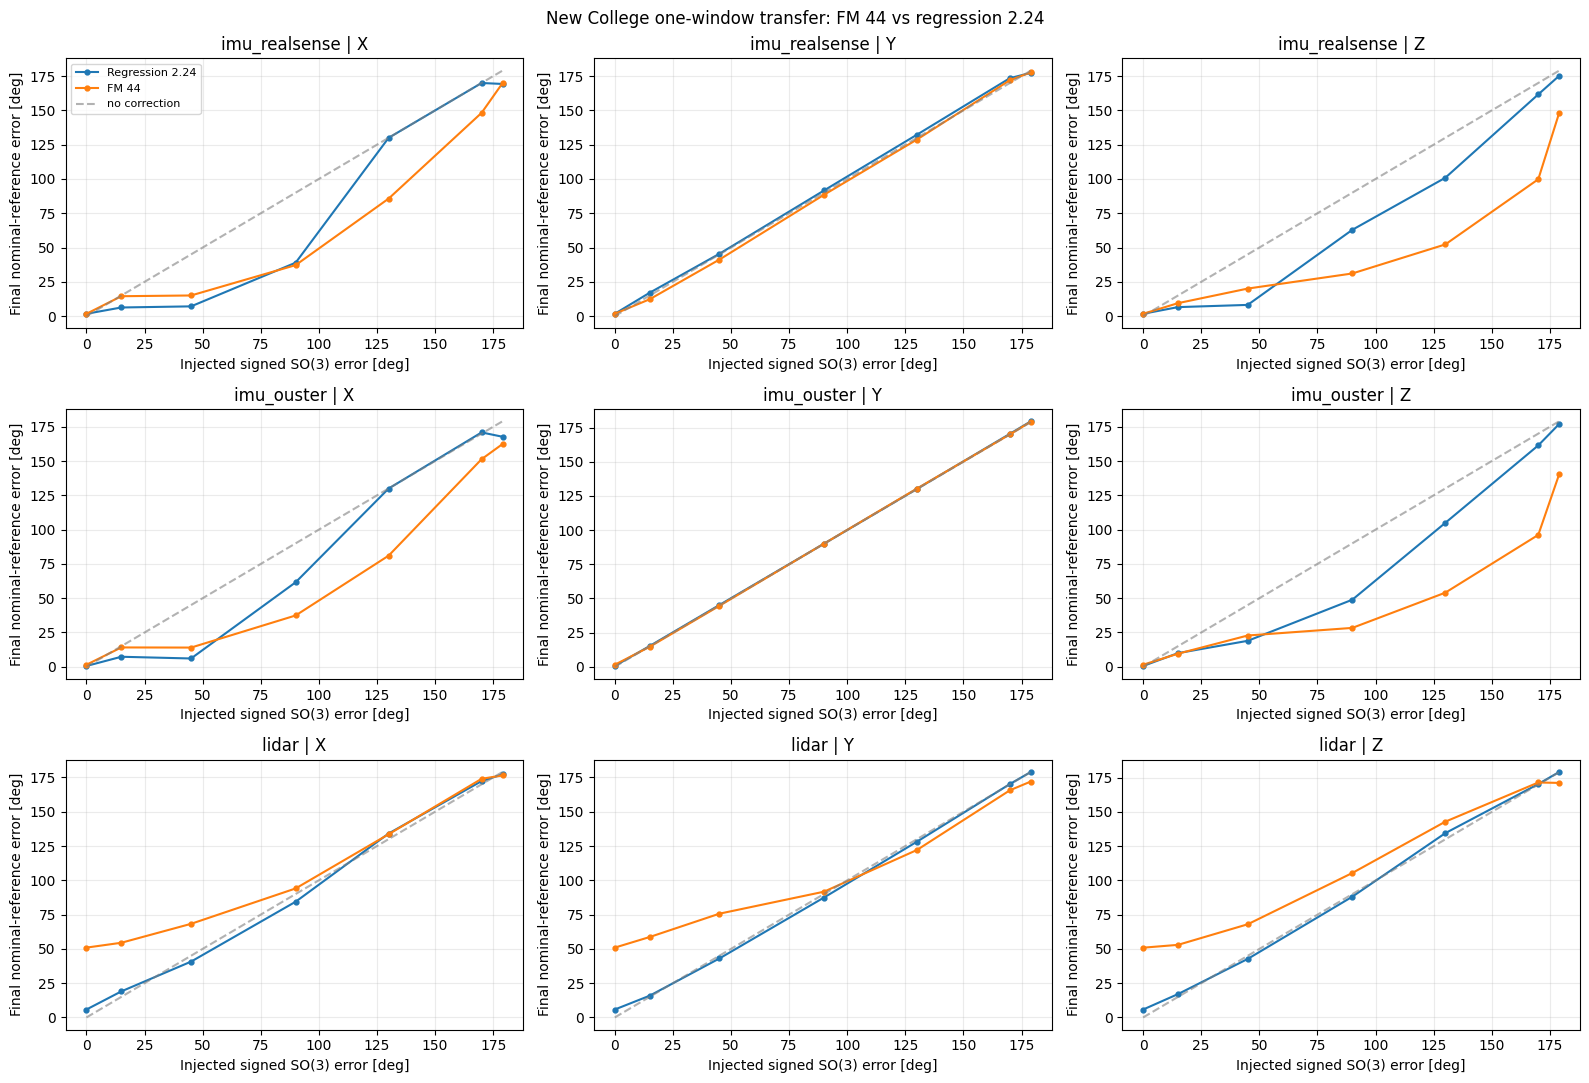

In [11]:
if not one_step.empty:
    subset = one_step[one_step.scenario == 'rotation_only']
    fig, axes = plt.subplots(len(CALIBRATION_KEYS), 3, figsize=(16, 11), squeeze=False)
    for r, sensor in enumerate(CALIBRATION_KEYS):
        for c, axis in enumerate('xyz'):
            ax = axes[r, c]
            group = subset[(subset.sensor == sensor) & (subset.axis == axis)]
            for model_name in MODEL_LABELS:
                means = group[group.model == model_name].groupby('signed_initial_deg').after_deg.mean().sort_index()
                ax.plot(means.index, means.values, '-o', ms=3.5, label=model_name)
            ax.plot([0, 179], [0, 179], '--', color='gray', alpha=.6, label='no correction')
            ax.set(title=f'{sensor} | {axis.upper()}', xlabel='Injected signed SO(3) error [deg]', ylabel='Final nominal-reference error [deg]')
            ax.grid(alpha=.25)
            if r == 0 and c == 0:
                ax.legend(fontsize=8)
    fig.suptitle('New College one-window transfer: FM 44 vs regression 2.24')
    fig.tight_layout()
    if SAVE_RESULTS:
        fig.savefig(OUT / 'one_step_rotation_transfer.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

## 10. Chronological single-sensor rollouts (notebook 36 / 32 protocol)

Take a continuous segment of genuine New College measurements. Initialize **the same one-sensor fault** for both models, then carry separate predictions window to window. Other sensors stay at their nominal reference states. A stable result must stay under the configured threshold for the last `STABLE_LAST_N_WINDOWS`, not merely cross the threshold once.

In [12]:
rollout_end = len(nc_dataset) if ROLLOUT_NUM_WINDOWS is None else min(len(nc_dataset), ROLLOUT_START + ROLLOUT_NUM_WINDOWS)
selected_rollout_indices = [ROLLOUT_START]
for index in range(ROLLOUT_START + 1, rollout_end):
    if abs(window_starts[index] - window_starts[selected_rollout_indices[-1]] - WINDOW_STRIDE_S) > 1e-4:
        print(f'Contiguous segment ends at {index}; skipping remaining windows rather than stitching across a gap.')
        break
    selected_rollout_indices.append(index)
if len(selected_rollout_indices) < STABLE_LAST_N_WINDOWS:
    raise ValueError('Not enough contiguous windows for stable convergence test. Adjust ROLLOUT_START or STABLE_LAST_N_WINDOWS.')
rollout_windows = [to_device(nc_dataset[index]) for index in selected_rollout_indices]
print(f'Sequential segment: {len(rollout_windows)} physical windows, [{window_starts[selected_rollout_indices[0]]:.1f}, {window_starts[selected_rollout_indices[-1]]+WINDOW_DURATION_S:.1f}] s')

@torch.inference_mode()
def run_single_sensor_rollout(sensor, scenario, rotation_vector_deg, tau_ms, axis_label):
    reference = reference_states(rollout_windows[0])
    initial = perturb_one(reference, sensor, rotation_vector_deg, tau_ms=tau_ms)
    carries = {label: clone_states(initial) for label in MODEL_LABELS}
    initial_error_deg, initial_tau_error_ms = errors(initial, reference, sensor)
    base = dict(sensor=sensor, scenario=scenario, axis=axis_label, rotvec_deg=str(tuple(map(float,rotation_vector_deg))),
                initial_angle_deg=float(np.linalg.norm(rotation_vector_deg)), initial_tau_ms=float(tau_ms))
    rows = [dict(**base, model=label, step=0, window_index=selected_rollout_indices[0], elapsed_s=0.0,
                 rotation_error_deg=initial_error_deg, tau_error_ms=initial_tau_error_ms, predicted_step_deg=0.0, status='ok') for label in MODEL_LABELS]
    for step, (index, window) in enumerate(zip(selected_rollout_indices, rollout_windows), start=1):
        for label, model in BACKBONES.items():
            state = carries[label]
            result = calibration_forward(window, state, model)
            updated = apply_single_update(state, result, sensor, update_rotation=scenario != 'tau_only', update_tau=scenario != 'rotation_only')
            assert_healthy_sensors_unchanged(reference, updated, sensor)
            rotation_error, tau_error = errors(updated, reference, sensor)
            if not np.isfinite(rotation_error) or not np.isfinite(tau_error):
                raise FloatingPointError(f'Nonfinite {label} state at window {index}')
            predicted_deg = float(torch.rad2deg(result.predictions[sensor].delta_xi[:, :3].norm(dim=-1)).item())
            rows.append(dict(**base, model=label, step=step, window_index=index, elapsed_s=float(window_starts[index] + WINDOW_DURATION_S - window_starts[selected_rollout_indices[0]]),
                             rotation_error_deg=rotation_error, tau_error_ms=tau_error, predicted_step_deg=predicted_deg, status='ok'))
            carries[label] = updated
    return rows

scenarios = []
for sensor in CALIBRATION_KEYS:
    for angle in ROLLOUT_ANGLES_DEG:
        for axis in ROLLOUT_AXES if angle != 0 else (ROLLOUT_AXES[0],):
            for sign in (ROLLOUT_SIGNS if angle else (1,)):
                rv = np.zeros(3)
                rv[axis] = sign * angle
                scenarios.append((sensor, 'rotation_only', tuple(rv), 0., 'xyz'[axis] if angle else 'zero'))
    if RUN_MIXED_ROLLOUTS:
        for rv in MIXED_ROTVEC_DEG:
            for tau in MIXED_TAU_MS:
                scenarios.append((sensor, 'mixed', tuple(rv), tau, 'mixed'))
    if RUN_TAU_ONLY_ROLLOUTS:
        for tau in ROLLOUT_TAU_ONLY_MS:
            scenarios.append((sensor, 'tau_only', (0., 0., 0.), tau, 'tau'))

if RUN_SINGLE_SENSOR_ROLLOUTS:
    all_rows = []
    for sensor, scenario, rotvec, tau_ms, axis in tqdm(scenarios, desc='Matched NewCollege rollouts'):
        all_rows.extend(run_single_sensor_rollout(sensor, scenario, rotvec, tau_ms, axis))
    rollouts = pd.DataFrame(all_rows)
    group_columns = ['model', 'sensor', 'scenario', 'axis', 'rotvec_deg', 'initial_tau_ms']
    summary_rows = []
    for labels, group in rollouts.groupby(group_columns, dropna=False):
        group = group.sort_values('step')
        mode = group.scenario.iloc[0]
        tail = group.iloc[-min(STABLE_LAST_N_WINDOWS, len(group)-1):]
        stable_rotation = (mode == 'tau_only') or bool((tail.rotation_error_deg < ROTATION_CONVERGENCE_DEG).all())
        stable_tau = (mode == 'rotation_only') or bool((tail.tau_error_ms < TAU_CONVERGENCE_MS).all())
        summary_rows.append(dict(zip(group_columns, labels), initial_rotation_deg=float(group.rotation_error_deg.iloc[0]),
                                 final_rotation_deg=float(group.rotation_error_deg.iloc[-1]), min_rotation_deg=float(group.rotation_error_deg.iloc[1:].min()),
                                 final_tau_ms=float(group.tau_error_ms.iloc[-1]), stable_convergence=stable_rotation and stable_tau))
    rollout_summary = pd.DataFrame(summary_rows)
    display(rollout_summary.groupby(['model', 'scenario'])[['final_rotation_deg', 'final_tau_ms', 'stable_convergence']].agg(['count','mean','median']).round(3))
    display(rollout_summary[rollout_summary.scenario == 'rotation_only'].groupby(['sensor', 'model', 'initial_rotation_deg']).agg(final_error=('final_rotation_deg','median'), stable_rate=('stable_convergence','mean')).round(3))
    if SAVE_RESULTS:
        rollouts.to_csv(OUT / 'chronological_rollouts.csv', index=False)
        rollout_summary.to_csv(OUT / 'chronological_rollout_summary.csv', index=False)
else:
    rollouts = pd.DataFrame()
    rollout_summary = pd.DataFrame()
    print('RUN_SINGLE_SENSOR_ROLLOUTS=False')

Sequential segment: 20 physical windows, [0.0, 100.0] s


Matched NewCollege rollouts:   0%|          | 0/75 [00:00<?, ?it/s]

final_rotation_deg                 final_tau_ms  \
                                           count    mean  median        count   
model           scenario                                                        
FM 44           mixed                         12  68.602  51.903           12   
                rotation_only                 57  82.490  82.330           57   
                tau_only                       6   0.000   0.000            6   
Regression 2.24 mixed                         12  59.961  52.134           12   
                rotation_only                 57  74.865  56.655           57   
                tau_only                       6   0.000   0.000            6   

                                              stable_convergence                
                                 mean  median              count   mean median  
model           scenario                                                        
FM 44           mixed          57.011  54.901                 12  0.000    0.0  
                rotation_only   0.000   0.000                 57  0.000    0.0  
                tau_only       37.468  12.741                  6  0.333    0.0  
Regression 2.24 mixed          66.832  36.498                 12  0.000    0.0  
                rotation_only   0.000   0.000                 57  0.035    0.0  
                tau_only       53.715  14.394                  6  0.333    0.0

final_error  stable_rate
sensor     model           initial_rotation_deg                          
imu_ouster FM 44           0.000000                   11.562          0.0
                           14.999999                  15.636          0.0
                           15.000001                  11.546          0.0
                           45.000000                  45.224          0.0
                           45.000004                  18.874          0.0
...                                                      ...          ...
lidar      Regression 2.24 130.000015                122.010          0.0
                           130.000031                128.445          0.0
                           170.000000                166.877          0.0
                           170.000015                169.266          0.0
                           179.000000                172.920          0.0

[76 rows x 2 columns]

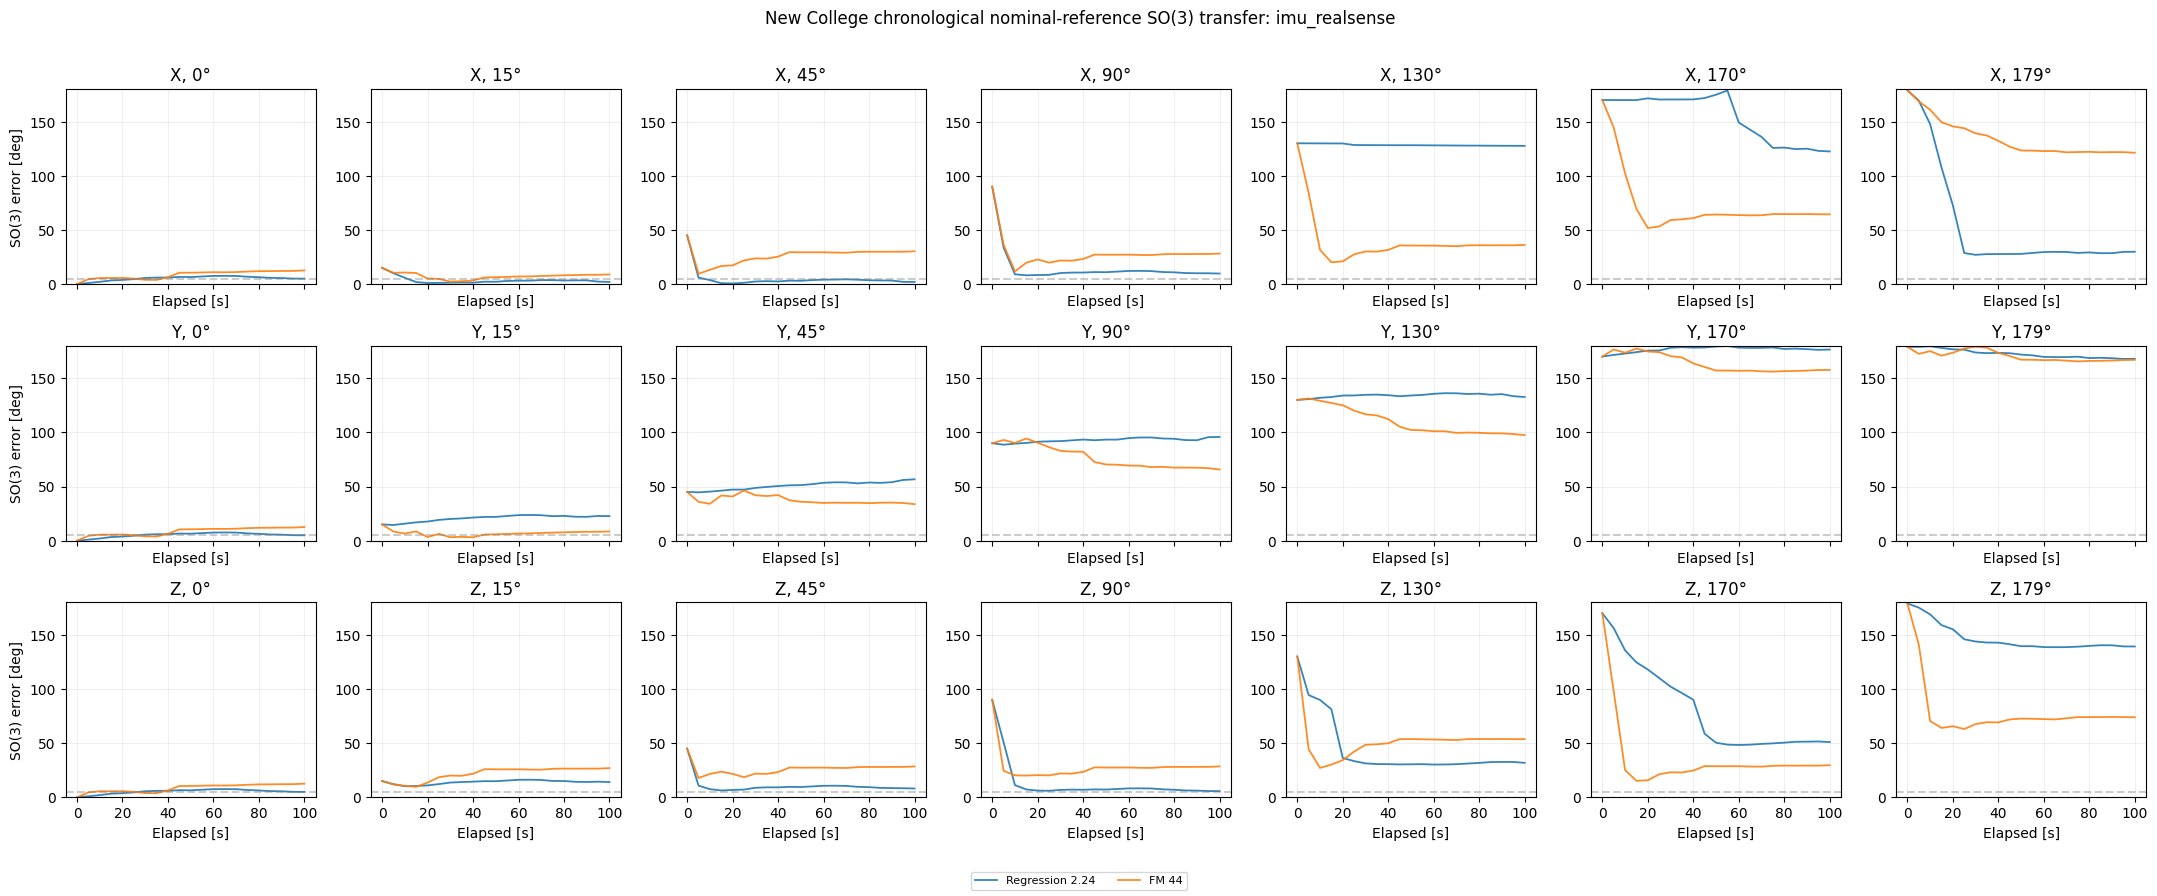

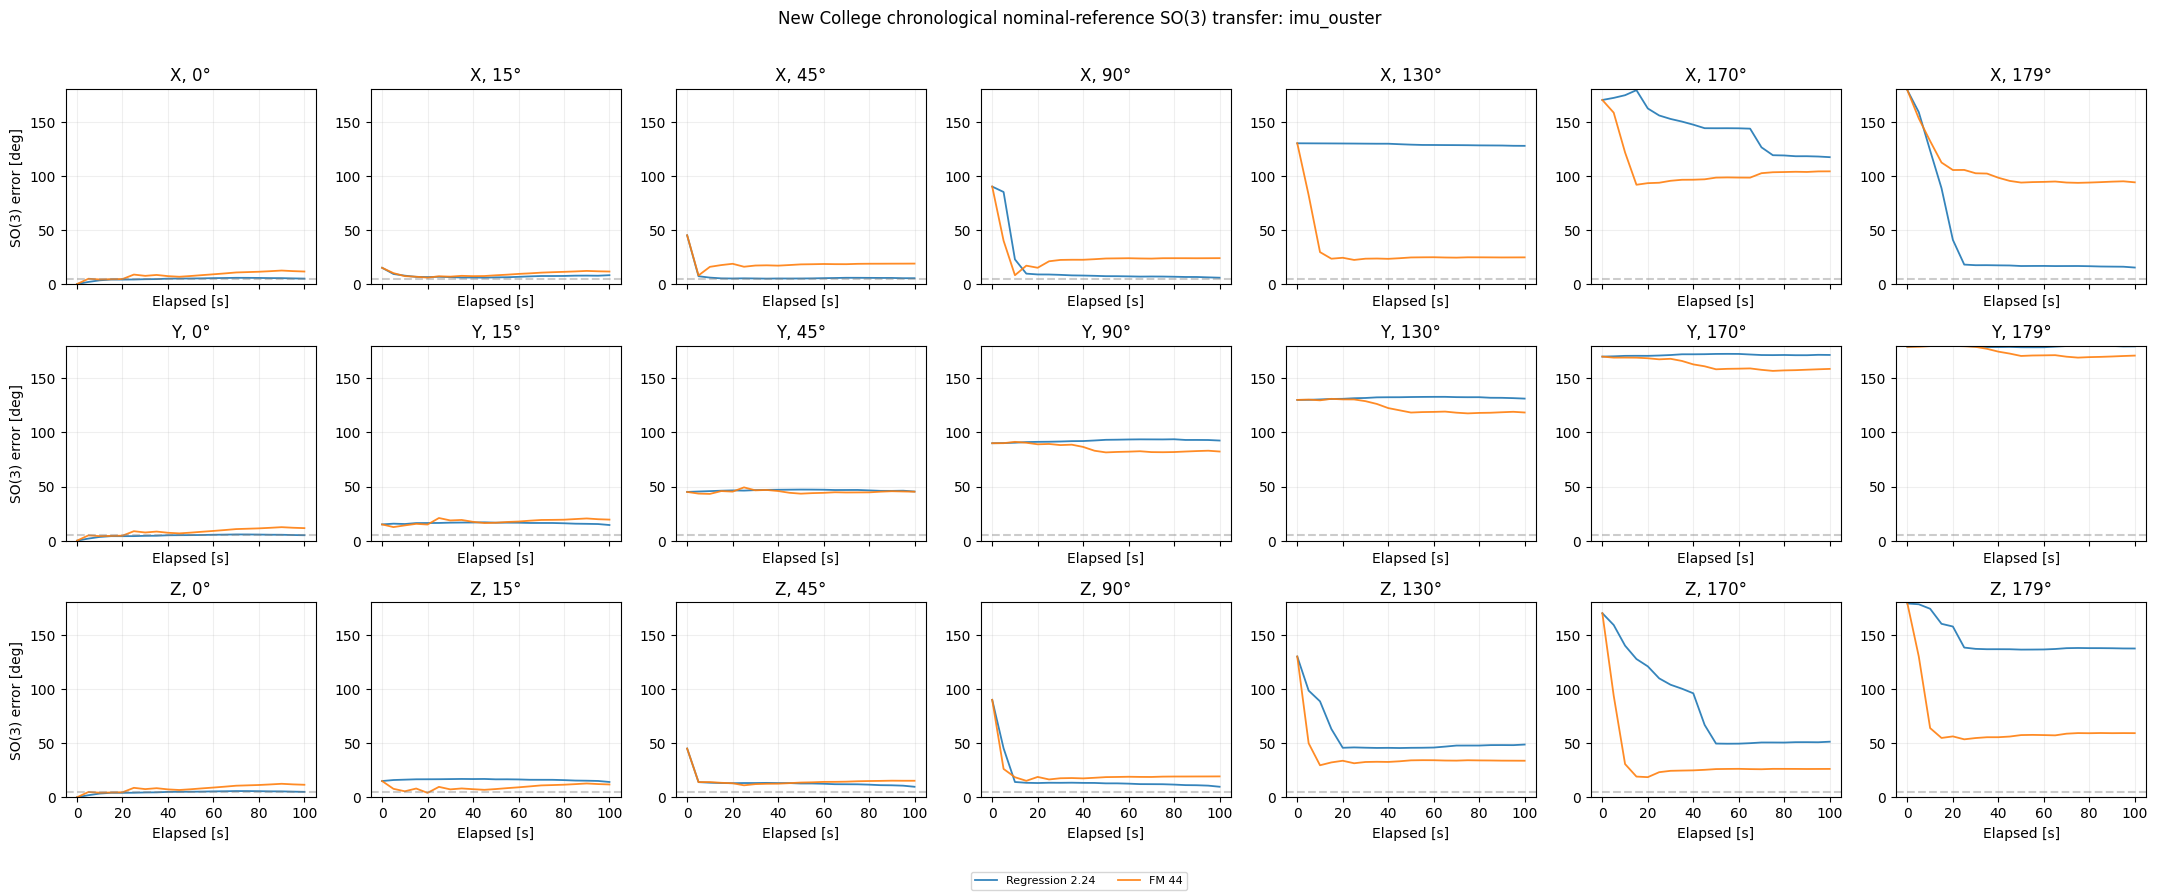

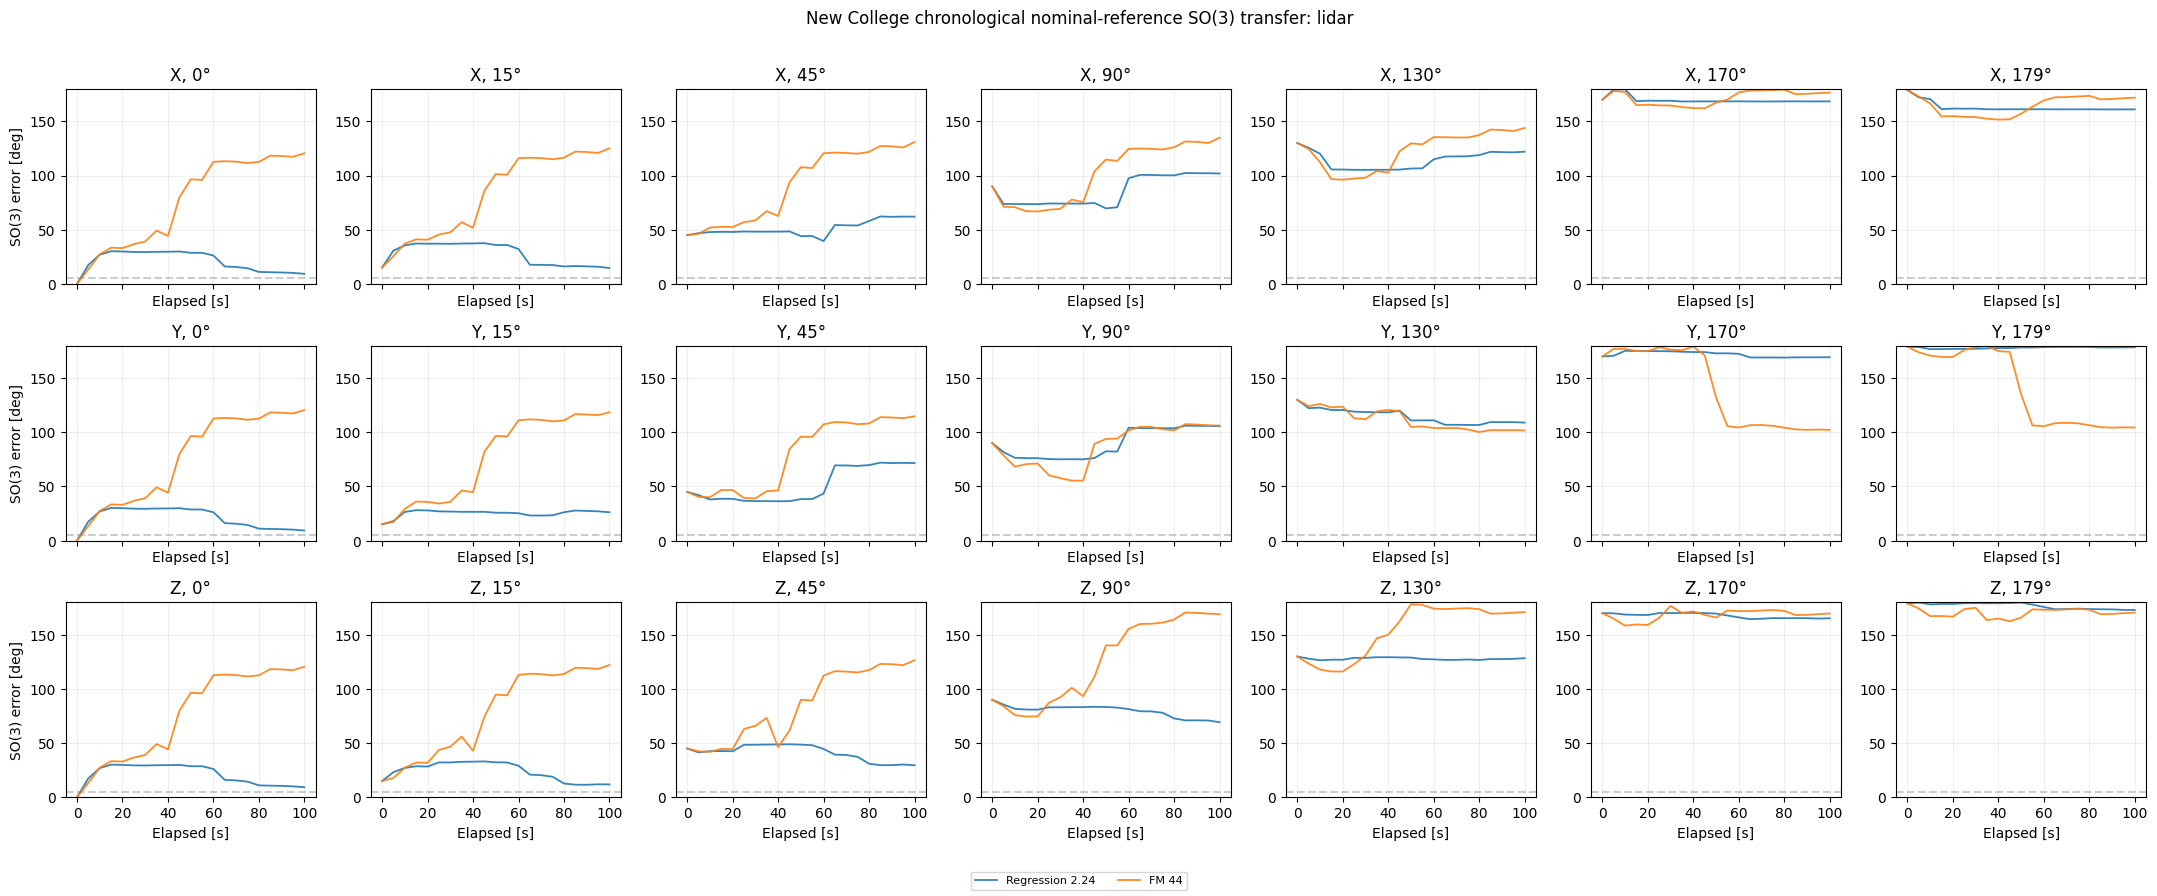

In [13]:
if not rollouts.empty:
    for sensor in CALIBRATION_KEYS:
        selected = rollouts[(rollouts.sensor == sensor) & (rollouts.scenario == 'rotation_only')]
        fig, axes = plt.subplots(3, len(ROLLOUT_ANGLES_DEG), figsize=(3.1 * len(ROLLOUT_ANGLES_DEG), 9), squeeze=False, sharex=True)
        for r, axis in enumerate('xyz'):
            for c, magnitude in enumerate(ROLLOUT_ANGLES_DEG):
                ax = axes[r, c]
                subset = selected[(selected.axis == ('zero' if magnitude == 0 else axis)) & (selected.initial_angle_deg == magnitude)]
                for label in MODEL_LABELS:
                    for _, group in subset[subset.model == label].groupby('rotvec_deg'):
                        group = group.sort_values('step')
                        ax.plot(group.elapsed_s, group.rotation_error_deg, label=label, linewidth=1.3, alpha=.9)
                ax.axhline(ROTATION_CONVERGENCE_DEG, color='gray', linestyle='--', alpha=.4)
                ax.set(title=f'{axis.upper()}, {magnitude:g}°', xlabel='Elapsed [s]', ylim=(0, 180))
                ax.grid(alpha=.2)
                if c == 0:
                    ax.set_ylabel('SO(3) error [deg]')
        handles, labels = axes[0, 0].get_legend_handles_labels()
        if handles:
            fig.legend(handles, labels, loc='lower center', ncol=2, fontsize=8)
        fig.suptitle(f'New College chronological nominal-reference SO(3) transfer: {sensor}')
        fig.tight_layout(rect=(0, .04, 1, .97))
        if SAVE_RESULTS:
            fig.savefig(OUT / f'rotation_rollouts_{sensor}.png', dpi=150, bbox_inches='tight')
        plt.show()
        plt.close(fig)

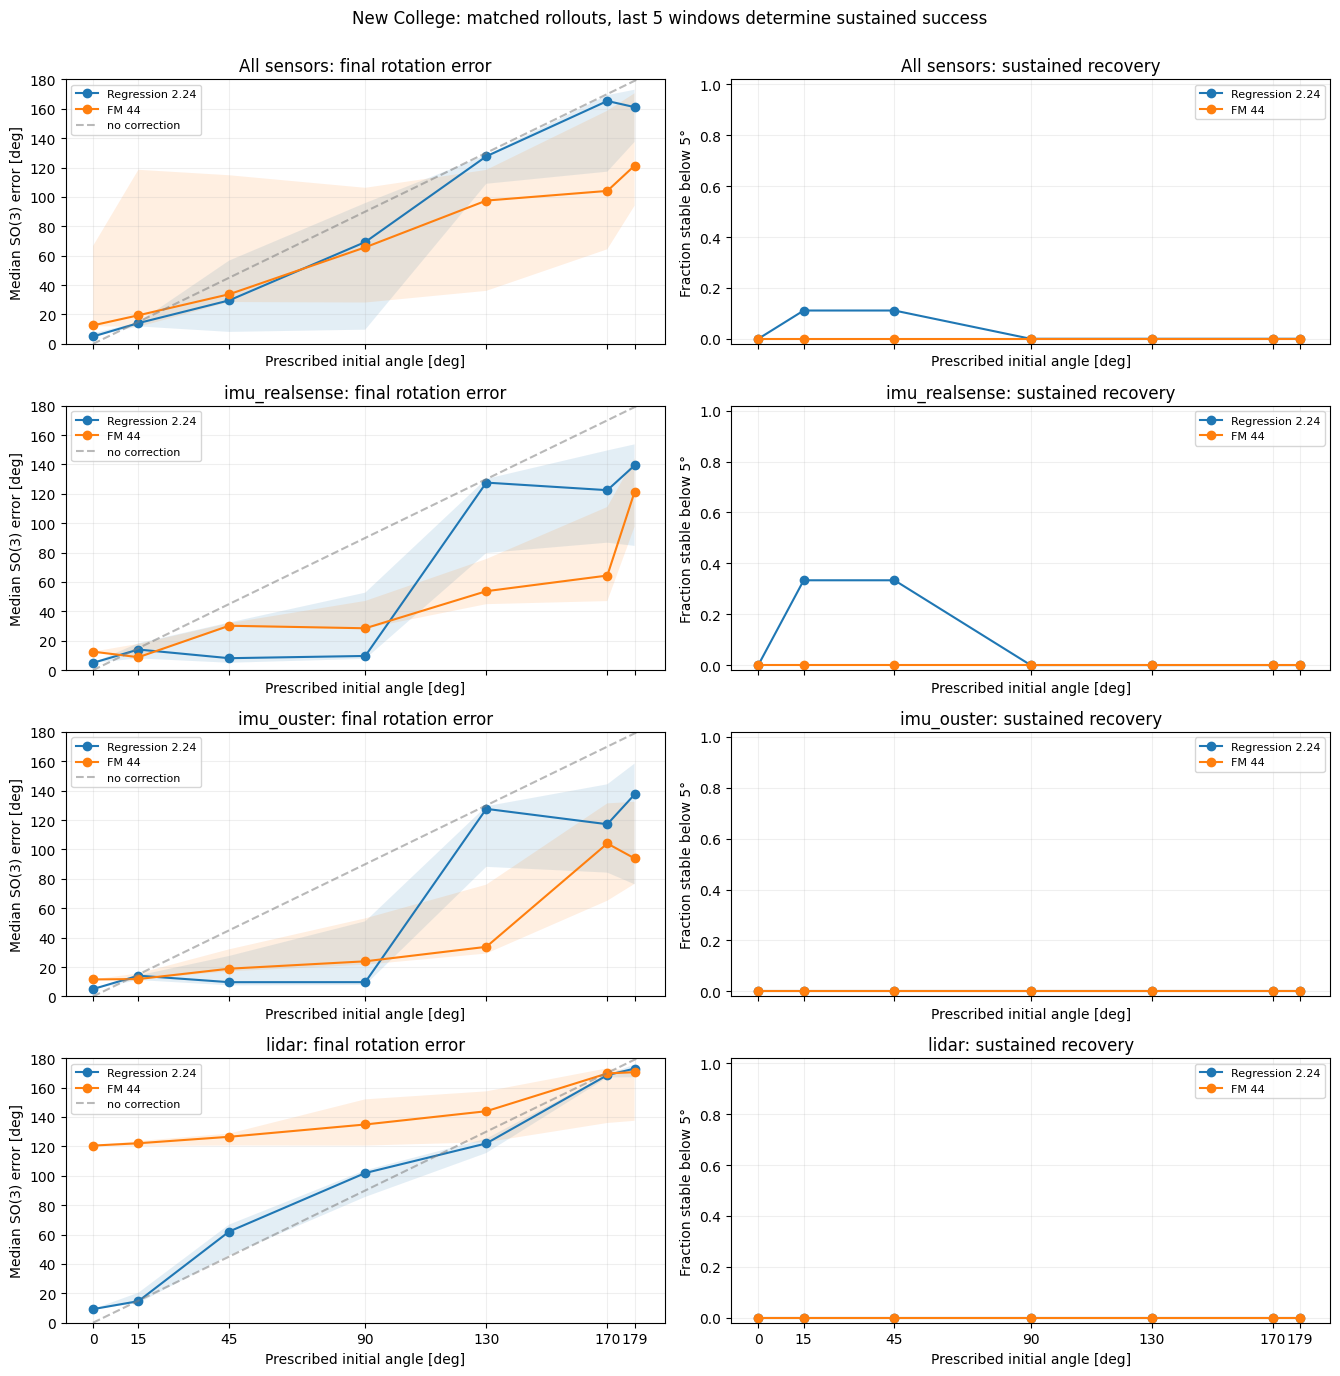

,sensor_group,model,nominal_angle_deg,cases,median_final_deg,stable_fraction
7,All sensors,FM 44,0.0,3,12.587,0.000
0,All sensors,Regression 2.24,0.0,3,5.015,0.000
8,All sensors,FM 44,15.0,9,19.438,0.000
1,All sensors,Regression 2.24,15.0,9,14.130,0.111
9,All sensors,FM 44,45.0,9,33.755,0.000
2,All sensors,Regression 2.24,45.0,9,29.588,0.111
10,All sensors,FM 44,90.0,9,65.701,0.000
3,All sensors,Regression 2.24,90.0,9,69.312,0.000
11,All sensors,FM 44,130.0,9,97.498,0.000
4,All sensors,Regression 2.24,130.0,9,127.617,0.000


In [14]:
# Notebook 45 replacement for the 'Transfer convergence / Sustained calibration recovery' summary.
# Run after the chronological rollouts; no model evaluation is repeated.
if rollout_summary.empty:
    print('No rollout summary available; run the chronological rollout cell first.')
else:
    rotation = rollout_summary.loc[rollout_summary.scenario == 'rotation_only'].copy()
    requested_angles = np.asarray(ROLLOUT_ANGLES_DEG, dtype=float)
    measured_angles = rotation.initial_rotation_deg.to_numpy(dtype=float)
    closest = np.abs(measured_angles[:, None] - requested_angles[None, :]).argmin(axis=1)
    deviations = np.abs(measured_angles - requested_angles[closest])
    if np.any(deviations > 0.1):
        raise ValueError(f'Unexpected initial angle (maximum discrepancy {deviations.max():.3f} deg)')
    rotation['nominal_angle_deg'] = requested_angles[closest]

    # Pool the distinct axes/signs ONLY after assigning them to the prescribed angle.
    # Also show each sensor independently to reveal topology-dependent failure modes.
    facets = [('All sensors', rotation)] + [(sensor, rotation.loc[rotation.sensor == sensor]) for sensor in CALIBRATION_KEYS]
    fig, axes = plt.subplots(len(facets), 2, figsize=(13.5, 3.5 * len(facets)), sharex=True, squeeze=False)
    comparison_rows = []
    for row_index, (facet_name, frame) in enumerate(facets):
        for model_name in MODEL_LABELS:
            data = frame.loc[frame.model == model_name]
            grouped = data.groupby('nominal_angle_deg', sort=True)
            if data.empty:
                continue
            medians = grouped.final_rotation_deg.median()
            lower = grouped.final_rotation_deg.quantile(0.25)
            upper = grouped.final_rotation_deg.quantile(0.75)
            stable = grouped.stable_convergence.mean()
            counts = grouped.size()
            angles = medians.index.to_numpy(dtype=float)
            axes[row_index, 0].plot(angles, medians.to_numpy(), '-o', label=model_name)
            axes[row_index, 0].fill_between(angles, lower.to_numpy(), upper.to_numpy(), alpha=0.12)
            axes[row_index, 1].plot(angles, stable.to_numpy(), '-o', label=model_name)
            for angle in angles:
                comparison_rows.append(dict(sensor_group=facet_name, model=model_name, nominal_angle_deg=angle,
                                            cases=int(counts.loc[angle]), median_final_deg=float(medians.loc[angle]),
                                            stable_fraction=float(stable.loc[angle])))
        axes[row_index, 0].plot([0, 180], [0, 180], '--', color='gray', alpha=0.55, label='no correction')
        axes[row_index, 0].set(title=f'{facet_name}: final rotation error', ylabel='Median SO(3) error [deg]', ylim=(0, 180))
        axes[row_index, 1].set(title=f'{facet_name}: sustained recovery', ylabel='Fraction stable below 5°', ylim=(-0.02, 1.02))
        for ax in axes[row_index]:
            ax.set_xticks(requested_angles)
            ax.set_xlabel('Prescribed initial angle [deg]')
            ax.grid(alpha=0.2)
        axes[row_index, 0].legend(fontsize=8)
        axes[row_index, 1].legend(fontsize=8)
    fig.suptitle(f'New College: matched rollouts, last {STABLE_LAST_N_WINDOWS} windows determine sustained success')
    fig.tight_layout(rect=(0, 0, 1, 0.98))
    if SAVE_RESULTS:
        fig.savefig(OUT / 'rollout_convergence_summary_fixed.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

    corrected_rollout_summary = pd.DataFrame(comparison_rows)
    display(corrected_rollout_summary.sort_values(['sensor_group', 'nominal_angle_deg', 'model']).round(3))
    if SAVE_RESULTS:
        corrected_rollout_summary.to_csv(OUT / 'rollout_convergence_summary_fixed.csv', index=False)


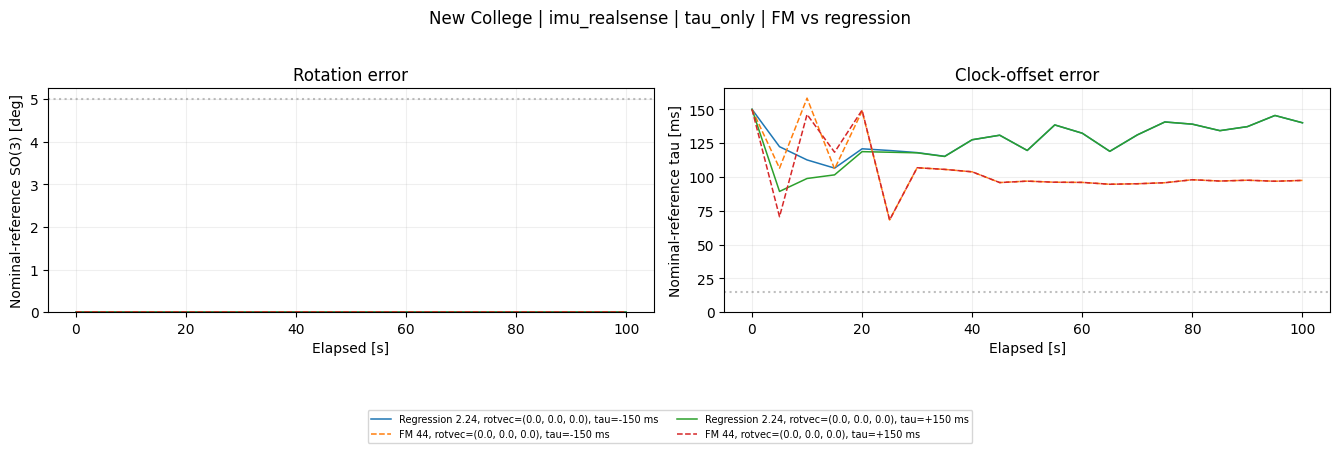

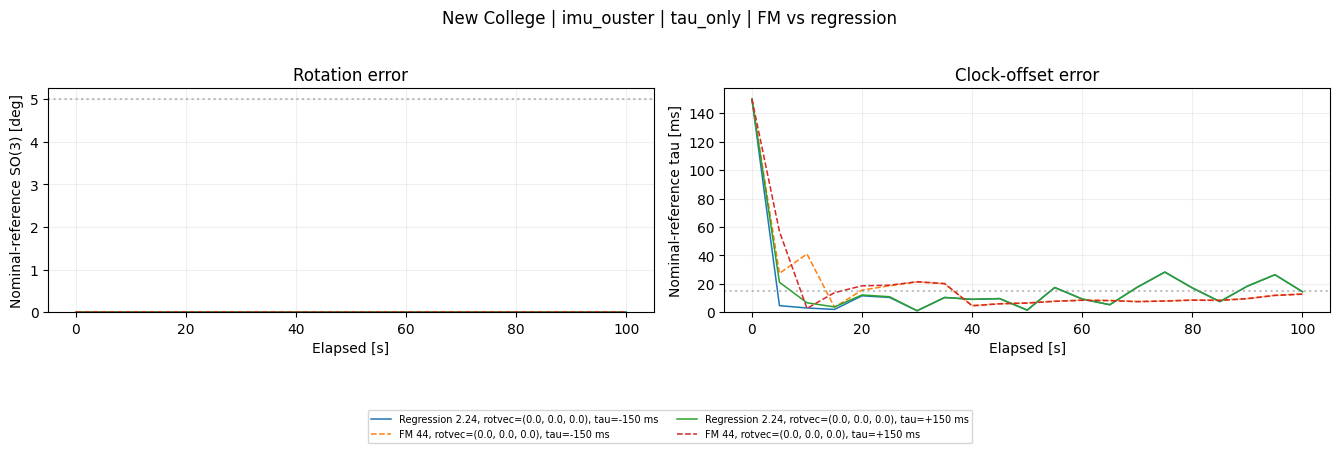

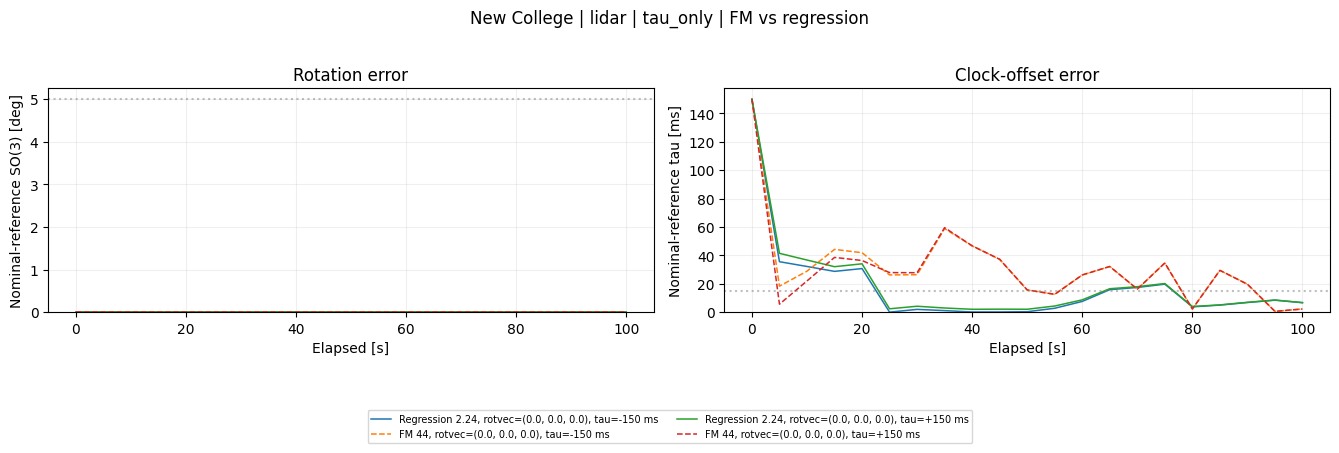

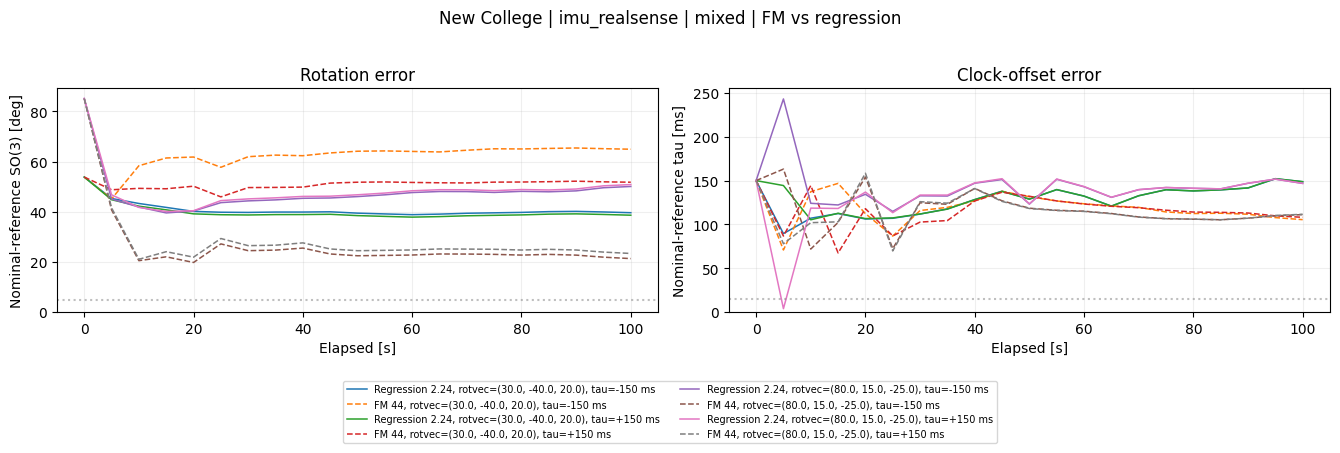

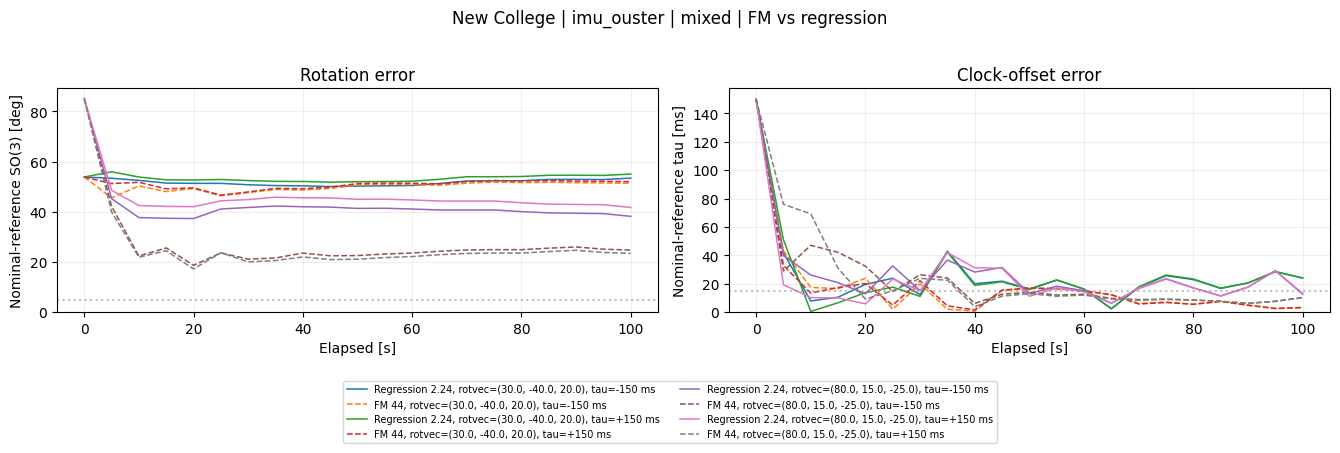

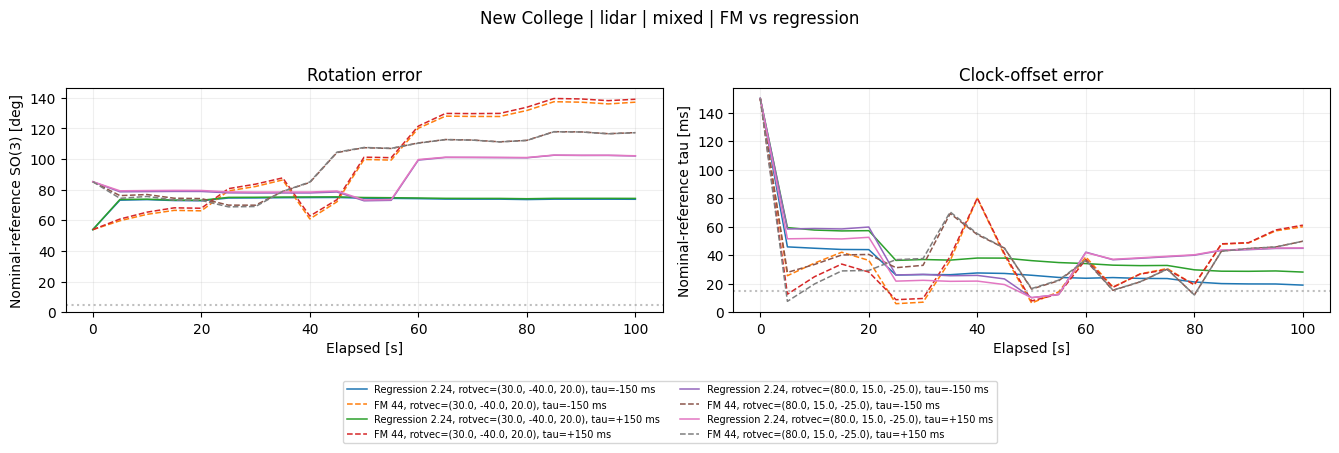

In [15]:
# Clock-offset and mixed-perturbation trajectories, paired on identical physical windows.
if not rollouts.empty:
    for scenario in ('tau_only', 'mixed'):
        frame = rollouts[rollouts.scenario == scenario]
        if frame.empty:
            continue
        for sensor in CALIBRATION_KEYS:
            subset = frame[frame.sensor == sensor]
            fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.3))
            for (model_name, rv, initial_tau_ms), group in subset.groupby(['model', 'rotvec_deg', 'initial_tau_ms'], sort=False):
                group = group.sort_values('step')
                style = '-' if model_name == MODEL_LABELS[0] else '--'
                label = f'{model_name}, rotvec={rv}, tau={initial_tau_ms:+g} ms'
                axes[0].plot(group.elapsed_s, group.rotation_error_deg, linestyle=style, label=label, linewidth=1.1)
                axes[1].plot(group.elapsed_s, group.tau_error_ms, linestyle=style, label=label, linewidth=1.1)
            axes[0].axhline(ROTATION_CONVERGENCE_DEG, linestyle=':', color='gray', alpha=.5)
            axes[1].axhline(TAU_CONVERGENCE_MS, linestyle=':', color='gray', alpha=.5)
            axes[0].set(title='Rotation error', ylabel='Nominal-reference SO(3) [deg]')
            axes[1].set(title='Clock-offset error', ylabel='Nominal-reference tau [ms]')
            for ax in axes:
                ax.set(xlabel='Elapsed [s]', ylim=(0, None))
                ax.grid(alpha=.2)
            fig.suptitle(f'New College | {sensor} | {scenario} | FM vs regression')
            fig.legend(*axes[1].get_legend_handles_labels(), loc='lower center', bbox_to_anchor=(.5, -.04), ncol=2, fontsize=7)
            fig.tight_layout(rect=(0, .14, 1, .96))
            if SAVE_RESULTS:
                fig.savefig(OUT / f'{scenario}_rollouts_{sensor}.png', dpi=150, bbox_inches='tight')
            plt.show()
            plt.close(fig)


## 11. Optional all-sensor out-of-distribution rollout

Initialize **all three physical sensors** with different rotation axes and time-offset signs. Both networks predict all keys from the **same pre-update state**, and then apply all corrections jointly (Jacobi update). Report both absolute nominal-reference errors and pairwise relative rotation errors, since common-body gauge can otherwise obscure a failure.

All-sensor OOD angle:   0%|          | 0/5 [00:00<?, ?it/s]

,model,angle_deg,tau_ms,max_rotation_deg,max_pairwise_rotation_deg,max_tau_error_ms,whole_rig_5deg,whole_rig_15ms
40,Regression 2.24,0.0,0.0,61.110,58.788,119.196,False,False
41,FM 44,0.0,0.0,100.102,136.408,103.522,False,False
82,Regression 2.24,0.0,150.0,18.257,13.921,127.191,False,False
83,FM 44,0.0,150.0,103.652,127.785,120.752,False,False
124,Regression 2.24,45.0,0.0,50.895,41.943,128.858,False,False
125,FM 44,45.0,0.0,137.120,146.648,111.430,False,False
166,Regression 2.24,45.0,150.0,50.719,50.102,130.107,False,False
167,FM 44,45.0,150.0,133.820,143.080,116.376,False,False
208,Regression 2.24,130.0,0.0,154.523,168.835,419.864,False,False
209,FM 44,130.0,0.0,147.271,169.776,110.116,False,False


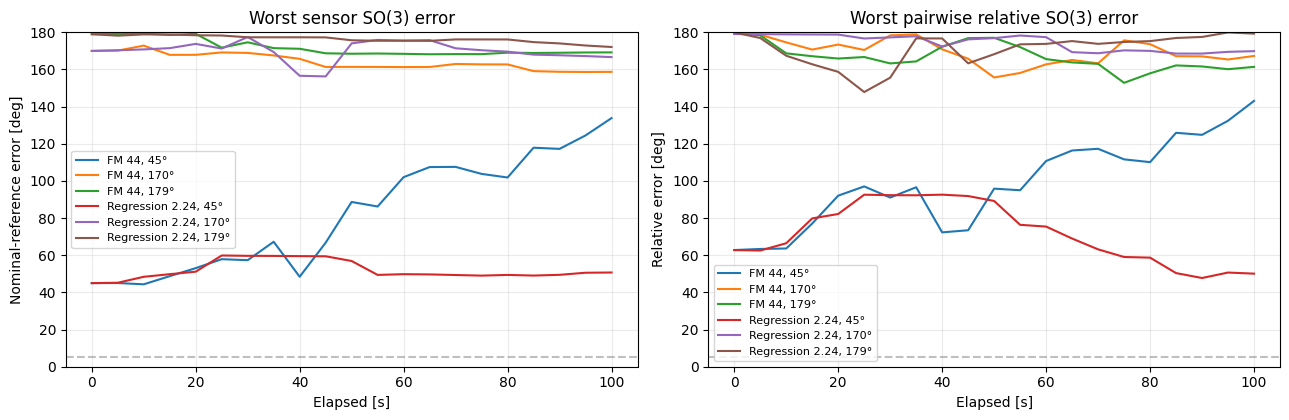

In [16]:
from itertools import combinations

@torch.inference_mode()
def pairwise_nominal_rotation_errors(states, reference):
    errors_by_pair = {}
    for first, second in combinations(CALIBRATION_KEYS, 2):
        observed = states[first].transform[:, :3, :3].transpose(-1, -2) @ states[second].transform[:, :3, :3]
        nominal = reference[first].transform[:, :3, :3].transpose(-1, -2) @ reference[second].transform[:, :3, :3]
        errors_by_pair[f'{first}|{second}'] = float(so3_error_deg(observed, nominal).item())
    return errors_by_pair

@torch.inference_mode()
def run_all_sensor_rollout(angle_deg, tau_ms):
    reference = reference_states(rollout_windows[0])
    starting = clone_states(reference)
    for index, sensor in enumerate(CALIBRATION_KEYS):
        direction = np.asarray(ALL_SENSOR_DIRECTIONS[sensor], dtype=float)
        direction = direction / np.linalg.norm(direction)
        perturbed = perturb_one(starting, sensor, direction * angle_deg, tau_ms * ((-1) ** index))
        starting[sensor] = perturbed[sensor]
    for sensor in CALIBRATION_KEYS:
        assert abs(errors(starting, reference, sensor)[0] - angle_deg) < .05
        assert abs(errors(starting, reference, sensor)[1] - abs(tau_ms)) < .02
    carries = {name: clone_states(starting) for name in MODEL_LABELS}
    rows = []
    for step in range(len(rollout_windows) + 1):
        for name, model in BACKBONES.items():
            current = carries[name]
            absolute = [errors(current, reference, key) for key in CALIBRATION_KEYS]
            relative = list(pairwise_nominal_rotation_errors(current, reference).values())
            rows.append(dict(model=name, angle_deg=angle_deg, tau_ms=tau_ms, step=step, elapsed_s=step * WINDOW_STRIDE_S,
                             max_rotation_deg=max(error[0] for error in absolute), mean_rotation_deg=np.mean([error[0] for error in absolute]),
                             max_tau_error_ms=max(error[1] for error in absolute), max_pairwise_rotation_deg=max(relative),
                             **{f'{key}_rotation_deg': errors(current, reference, key)[0] for key in CALIBRATION_KEYS}))
            if step == len(rollout_windows):
                continue
            window = rollout_windows[step]
            output = calibration_forward(window, current, model)
            updated = clone_states(current)
            for sensor in CALIBRATION_KEYS:
                # Each correction was predicted from the shared PRE-UPDATE state.
                revised = apply_single_update(current, output, sensor, update_rotation=True, update_tau=True)
                updated[sensor] = revised[sensor]
            carries[name] = updated
    return rows

if RUN_ALL_SENSOR_ROLLOUTS:
    records = []
    for angle in tqdm(ALL_SENSOR_ANGLES_DEG, desc='All-sensor OOD angle'):
        for tau in ALL_SENSOR_TAU_MS:
            records.extend(run_all_sensor_rollout(angle, tau))
    all_sensor_rollouts = pd.DataFrame(records)
    last = all_sensor_rollouts[all_sensor_rollouts.step == len(rollout_windows)].copy()
    last['whole_rig_5deg'] = last.max_rotation_deg < ROTATION_CONVERGENCE_DEG
    last['whole_rig_15ms'] = last.max_tau_error_ms < TAU_CONVERGENCE_MS
    display(last[['model','angle_deg','tau_ms','max_rotation_deg','max_pairwise_rotation_deg','max_tau_error_ms','whole_rig_5deg','whole_rig_15ms']].round(3))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
    for (model, angle, tau), group in all_sensor_rollouts.groupby(['model','angle_deg','tau_ms']):
        group = group.sort_values('step')
        if angle not in (45., 170., 179.) or tau != ALL_SENSOR_TAU_MS[-1]:
            continue
        axes[0].plot(group.elapsed_s, group.max_rotation_deg, label=f'{model}, {angle:g}°')
        axes[1].plot(group.elapsed_s, group.max_pairwise_rotation_deg, label=f'{model}, {angle:g}°')
    axes[0].set(title='Worst sensor SO(3) error', ylabel='Nominal-reference error [deg]')
    axes[1].set(title='Worst pairwise relative SO(3) error', ylabel='Relative error [deg]')
    for ax in axes:
        ax.set(xlabel='Elapsed [s]', ylim=(0, 180))
        ax.axhline(ROTATION_CONVERGENCE_DEG, color='gray', linestyle='--', alpha=.5)
        ax.grid(alpha=.25)
        ax.legend(fontsize=8)
    fig.tight_layout()
    if SAVE_RESULTS:
        all_sensor_rollouts.to_csv(OUT / 'all_sensor_ood_rollouts.csv', index=False)
        fig.savefig(OUT / 'all_sensor_ood_plot.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)
else:
    print('All-sensor OOD test disabled; enable RUN_ALL_SENSOR_ROLLOUTS to run.')

## 12. Parameter counts and measured inference latency

Report **model-only** latency on the exact same already-tokenized New College window and **end-to-end compute** (geometry + tokenization + prediction), excluding disk access. FM Lie-midpoint uses two velocity MLP evaluations per integration step; models need not have equal inference costs.

In [17]:
def sync_device():
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize(DEVICE)

@torch.inference_mode()
def timed_call(fn, warmup=BENCHMARK_WARMUP, repeats=BENCHMARK_REPEATS):
    for _ in range(warmup):
        fn()
    sync_device()
    milliseconds = []
    for _ in range(repeats):
        sync_device()
        start = time.perf_counter()
        fn()
        sync_device()
        milliseconds.append(1000 * (time.perf_counter() - start))
    return float(np.median(milliseconds))

rows = []
for label, model in BACKBONES.items():
    model_only = []
    complete = []
    for index in np.unique(np.linspace(0, len(nc_dataset) - 1, min(BENCHMARK_NUM_WINDOWS, len(nc_dataset)), dtype=int)):
        window = to_device(nc_dataset[int(index)])
        tokens, context = tokenize_candidate(window, window.current_calibration)
        model_only.append(timed_call(lambda m=model, t=tokens, c=context: predict_from_tokens(m, t, c)))
        complete.append(timed_call(lambda m=model, w=window: calibration_forward(w, w.current_calibration, m)))
    rows.append(dict(model=label, total_parameters=sum(p.numel() for p in model.parameters()),
                     velocity_or_regression_head_parameters=sum(p.numel() for p in model.head.parameters()),
                     model_only_ms_per_window=float(np.median(model_only)), geometry_token_model_ms_per_window=float(np.median(complete)),
                     network_function_evaluations=2 * FM_INTEGRATION_STEPS if isinstance(model, PooledCalibrationFlowModel) and FM_INTEGRATION_METHOD == 'midpoint' else (FM_INTEGRATION_STEPS if isinstance(model, PooledCalibrationFlowModel) else 1)))
timings = pd.DataFrame(rows)
display(timings.round(3))
if SAVE_RESULTS:
    timings.to_csv(OUT / 'model_latency_and_parameters.csv', index=False)

,model,total_parameters,velocity_or_regression_head_parameters,model_only_ms_per_window,geometry_token_model_ms_per_window,network_function_evaluations
0,Regression 2.24,2554505,25353,33.261,43.002,1
1,FM 44,2555399,26247,202.592,215.428,32


## 13. Interpretation checklist

- **Domain shift:** KAIST training uses one IMU plus two LiDARs; New College has two IMUs and one genuine Ouster LiDAR. Report results by *physical sensor* and by axis, not just aggregate means.
- **Reference validity:** nominal extrinsics are not certified truth; nominal tau errors are conditional on provisional clock choices. Real calibration quality would need independent validation.
- **Controlled single faults:** the two untouched sensors remain nominal, an oracle advantage; only the all-sensor section probes simultaneous bad priors.
- **Rollout criterion:** a single lucky improvement is not convergence; use last-N-window stable success and check zero-error drift and 179° behavior.
- **Fair architecture comparison:** both checkpoints were trained on different corruption distributions; New College is a matched transfer comparison, not a causal proof of FM superiority.
- **Compute:** FM integration is substantially more expensive. Report performance together with NFE and measured wall-clock time.

**Recommended follow-up:** if FM generalizes on New College, repeat with random signed axes and multiple motion segments, then train a regression baseline with identical fine/coarse augmentations on KAIST before claiming an architectural FM gain.

In [18]:

@torch.inference_mode()
def probe_lidar_flow_integration():
    cases = []
    selected_windows = sorted(set((0, len(nc_dataset) // 2)))

    for window_index in selected_windows:
        window = to_device(nc_dataset[window_index])
        reference = reference_states(window)

        for angle_deg in (0.0, 15.0, 45.0, 90.0, 130.0, 170.0):
            for axis_index in ((0,) if angle_deg == 0.0 else (0, 1, 2)):
                rotvec = np.zeros(3)
                rotvec[axis_index] = angle_deg

                initial = perturb_one(reference, "lidar", rotvec)
                tokens, context = tokenize_candidate(window, initial)

                models = [
                    ("Regression", regression_model, None, None),
                    ("FM Euler-1", fm_model, 1, "euler"),
                    ("FM midpoint-4", fm_model, 4, "midpoint"),
                    ("FM midpoint-16", fm_model, 16, "midpoint"),
                ]

                for label, model, steps, method in models:
                    prediction = model(tokens, context) if steps is None else model(tokens, context, num_steps=steps, method=method)
                    corrected = apply_single_update(initial, prediction, "lidar", update_rotation=True, update_tau=False)

                    initial_error, _ = errors(initial, reference, "lidar")
                    final_error, _ = errors(corrected, reference, "lidar")
                    predicted_step_deg = torch.rad2deg(torch.linalg.vector_norm(prediction.predictions["lidar"].delta_xi[:, :3], dim=-1)).mean().item()

                    cases.append(dict(
                        window_index=window_index,
                        axis="xyz"[axis_index],
                        angle_deg=angle_deg,
                        model=label,
                        initial_deg=initial_error,
                        final_deg=final_error,
                        correction_deg=predicted_step_deg,
                        improved=final_error < initial_error,
                    ))

    result = pd.DataFrame(cases)
    display(result.groupby(["angle_deg", "model"])[["final_deg", "correction_deg", "improved"]].mean().round(3))
    return result

lidar_flow_probe = probe_lidar_flow_integration()


final_deg  correction_deg  improved
angle_deg model                                              
0.0       FM Euler-1         30.548          30.548     0.000
          FM midpoint-16     41.040          41.040     0.000
          FM midpoint-4      37.203          37.203     0.000
          Regression         11.168          11.168     0.000
15.0      FM Euler-1         36.554          29.610     0.000
          FM midpoint-16     45.781          40.044     0.000
          FM midpoint-4      42.223          36.209     0.000
          Regression         20.093          11.385     0.000
45.0      FM Euler-1         56.405          27.132     0.333
          FM midpoint-16     62.485          37.442     0.333
          FM midpoint-4      59.955          33.699     0.333
          Regression         41.892           9.603     0.833
90.0      FM Euler-1         89.724          23.417     0.500
          FM midpoint-16     90.331          33.383     0.500
          FM midpoint-4      89.897          29.681     0.500
          Regression         85.287          11.202     0.833
130.0     FM Euler-1        126.597          23.034     0.667
          FM midpoint-16    125.640          32.606     0.667
          FM midpoint-4     125.880          29.190     0.667
          Regression        129.264           7.455     0.500
170.0     FM Euler-1        168.264          22.877     0.333
          FM midpoint-16    168.025          29.962     0.500
          FM midpoint-4     167.987          26.954     0.500
          Regression        172.095           6.787     0.333